# 02 – Registres publics et réseau

**Développeur 2 :** M'BEY Max  
**Projet :** UE Data Mining 2026-2027 – section destinée au notebook final commun.

**Fichiers de départ :** `registered_entities.csv`, `officer_filings.csv`, `public_appointments.csv`, `licensed_professionals.csv`, `licensed_facilities.csv` (registres), `clinical_encounters.csv`, `clinical_procedures.csv` (santé), `erp_business_partners.csv`, `erp_facilities.csv` (logistique).

**Clés utilisées :**

| Lien | Clé source | Clé cible |
|---|---|---|
| Mandat → organisation | `officer_filings.registration_number` | `registered_entities.registration_number` |
| Établissement → organisation | `licensed_facilities.operating_organization_registration` | `registered_entities.registration_number` |
| Professionnel → établissement | `licensed_professionals.primary_facility_license` | `licensed_facilities.facility_license_number` |
| Rencontre → praticien / lieu | `attending_license_number`, `facility_license_number` | `license_number`, `facility_license_number` |
| Procédure → praticien / lieu | `performing_license_number`, `performing_facility_license` | `license_number`, `facility_license_number` |
| Partenaire ERP → organisation | `erp_business_partners.external_registration_number` | `registered_entities.registration_number` |

**Principe de prudence :** deux noms identiques ou proches ne désignent pas forcément la même personne. Chaque correspondance reçoit un niveau de confiance fondé sur des critères explicites (nom, année de naissance, région, cohérence des dates). Les données et le récit sont entièrement fictifs.

## 0. Chargement des données

In [1]:
import re
import unicodedata
from difflib import SequenceMatcher
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

DATA = Path("data")
OUT = Path("outputs") / "registres"
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "entities": "public_records/registered_entities.csv",
    "officers": "public_records/officer_filings.csv",
    "appointments": "public_records/public_appointments.csv",
    "professionals": "public_records/licensed_professionals.csv",
    "facilities": "public_records/licensed_facilities.csv",
    "encounters": "health/clinical_encounters.csv",
    "procedures": "health/clinical_procedures.csv",
    "partners": "logistics/erp_business_partners.csv",
    "erp_facilities": "logistics/erp_facilities.csv",
}

# tout lire en texte pour controler soi-meme les conversions de dates et de nombres
raw = {}
for name in FILES:
    raw[name] = pd.read_csv(DATA / FILES[name], dtype=str)

# premier apercu de la taille de chaque fichier
overview = []
for name in raw:
    df = raw[name]
    overview.append({
        "table": name,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "cellules vides": int(df.isna().sum().sum())
    })
pd.DataFrame(overview).set_index("table")

,lignes,colonnes,cellules vides
table,,,
entities,24,10,24
officers,136,12,77
appointments,62,12,77
professionals,53,10,79
facilities,3,12,3
encounters,1069,12,243
procedures,311,14,317
partners,80,11,15
erp_facilities,30,11,1


## 1. Découvrir et nettoyer les registres

Contrôles réalisés avant toute jointure :

1. **Texte** : espaces multiples, espaces en fin de chaîne, casse incohérente (ex. un intitulé de poste entièrement en minuscules).
2. **Dates** : plusieurs formats coexistent (`AAAA-MM-JJ`, `AAAA/MM/JJ`, `JJ/MM/AAAA`). On les convertit avec un parseur qui accepte ces formats, puis on vérifie qu'aucune date non vide n'a été perdue.
3. **Années de naissance** : `officer_filings` contient soit une année (`1961`) soit une tranche (`1920–1929`). On les représente par un intervalle `[birth_min, birth_max]` pour pouvoir comparer prudemment.
4. **Clés et doublons** : unicité des clés primaires, doublons exacts hors identifiant.
5. **Valeurs manquantes** et **incohérences logiques** (fin avant début).

In [2]:
def clean_text(value):
    """
    Retirer les espaces en trop d'une valeur texte.
    Retourne NaN si la valeur est vide.
    """
    if (pd.isna(value)):
        return np.nan
    text = unicodedata.normalize("NFKC", str(value))
    # split puis join supprime les espaces multiples et ceux des extremites
    text = " ".join(text.split())
    if (text == ""):
        return np.nan
    return text


def parse_dates(series):
    """
    Convertir une colonne de dates ecrites dans plusieurs formats
    (AAAA-MM-JJ, AAAA/MM/JJ, JJ/MM/AAAA) en dates pandas.
    """
    # dayfirst ne sert que pour les dates ambigues du type JJ/MM/AAAA
    return pd.to_datetime(series, format="mixed", dayfirst=True, errors="coerce")


def text_issues(df):
    """
    Compter, pour chaque colonne, les valeurs qui changent apres nettoyage.
    """
    rows = []
    for col in df.columns:
        values = df[col].dropna()
        count = 0
        for value in values:
            if (value != clean_text(value)):
                count += 1
        if (count > 0):
            rows.append({"colonne": col, "espaces superflus": count})
    return pd.DataFrame(rows)


for name in ["entities", "officers", "appointments", "professionals", "facilities"]:
    issues = text_issues(raw[name])
    if (len(issues) > 0):
        print(f"--- {name}")
        print(issues.to_string(index=False))

--- officers
  colonne  espaces superflus
full_name                  1
--- appointments
         colonne  espaces superflus
institution_name                  1
--- professionals
  colonne  espaces superflus
specialty                  1


In [3]:
DATE_COLUMNS = {
    "entities": ["registration_date", "last_filing_date"],
    "officers": ["appointment_date", "cessation_date", "filing_date"],
    "appointments": ["appointment_start", "appointment_end"],
    "professionals": ["license_issue_date", "license_expiry_date"],
    "facilities": ["license_start", "license_end"],
    "encounters": ["encounter_start", "encounter_end", "follow_up_date"],
    "procedures": ["scheduled_time", "performed_time", "next_review_date"],
    "partners": ["onboarding_date"],
    "erp_facilities": ["opening_date"],
}

clean = {}
format_report = []
for name in raw:
    df = raw[name].copy()
    # nettoyer toutes les colonnes texte avant de convertir les dates
    for col in df.columns:
        df[col] = df[col].map(clean_text)

    for col in DATE_COLUMNS.get(name, []):
        original = df[col].astype("string")
        # reperer les dates qui ne sont pas au format AAAA-MM-JJ
        iso = original.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)
        non_iso = original.notna() & ~iso
        df[col] = parse_dates(original)
        # une date non vide devenue vide signifierait une conversion ratee
        failed = original.notna() & df[col].isna()
        format_report.append({
            "table": name,
            "colonne": col,
            "valeurs non vides": int(original.notna().sum()),
            "format non ISO": int(non_iso.sum()),
            "exemples non ISO": ", ".join(original[non_iso].head(3)),
            "échecs de conversion": int(failed.sum())
        })
    clean[name] = df

fmt = pd.DataFrame(format_report)
fmt[fmt["format non ISO"] > 0]

,table,colonne,valeurs non vides,format non ISO,exemples non ISO,échecs de conversion
2,officers,appointment_date,136,1,1986/01/01,0
5,appointments,appointment_start,62,1,01/01/1974,0
7,professionals,license_issue_date,53,1,01/07/1994,0
11,encounters,encounter_start,1069,4,"19-Nov-2020 12:15:00, 19/12/2018 09:15:00, 15/02/2021 11...",0
12,encounters,encounter_end,1069,4,"28/12/2021 11:31:00, 06/08/2022 14:01:00, 2021/05/15 13:...",0
13,encounters,follow_up_date,829,2,"2020/02/22, 05-Apr-2023",0
14,procedures,scheduled_time,311,2,"2021/12/06 12:35:00, 09-Jul-2021 11:35:00",0
15,procedures,performed_time,311,1,2021/06/08 09:45:00,0
17,partners,onboarding_date,80,1,01/10/2003,0


In [4]:
print("Échecs de conversion de dates :", int(fmt["échecs de conversion"].sum()))

# un intitule de poste est ecrit entierement en minuscules
officers = clean["officers"]
lower_titles = officers["role_title"].str.match(r"^[a-z]")
print("Intitulés en minuscules :", officers.loc[lower_titles, "role_title"].tolist())
officers.loc[lower_titles, "role_title"] = officers.loc[lower_titles, "role_title"].str.capitalize()


def birth_interval(value):
    """
    Transformer une annee ("1961") ou une tranche ("1920–1929")
    en intervalle (annee_min, annee_max).
    """
    if (pd.isna(value)):
        return (np.nan, np.nan)
    years = []
    for year in re.findall(r"\d{4}", str(value)):
        years.append(int(year))
    return (min(years), max(years))


birth_min = []
birth_max = []
for value in officers["birth_year_or_age_band"]:
    low, high = birth_interval(value)
    birth_min.append(low)
    birth_max.append(high)
officers["birth_min"] = birth_min
officers["birth_max"] = birth_max

# cote nominations l'annee est exacte, donc min = max
appointments = clean["appointments"]
appointments["birth_min"] = pd.to_numeric(appointments["recorded_birth_year"])
appointments["birth_max"] = appointments["birth_min"]
officers[["birth_year_or_age_band", "birth_min", "birth_max"]].drop_duplicates().head(6)

Échecs de conversion de dates : 0
Intitulés en minuscules : ['research director at asterion clinical institute']


,birth_year_or_age_band,birth_min,birth_max
0,1815,1815,1815
1,1871,1871,1871
2,1920–1929,1920,1929
3,1961,1961,1961
4,1862,1862,1862
5,1900,1900,1900


In [5]:
PRIMARY_KEYS = {
    "entities": "registration_number",
    "officers": "filing_id",
    "appointments": "appointment_record_id",
    "professionals": "license_number",
    "facilities": "facility_license_number",
    "partners": "partner_code",
    "erp_facilities": "facility_code",
}

rows = []
for name in PRIMARY_KEYS:
    df = clean[name]
    key = PRIMARY_KEYS[name]
    # un doublon hors cle = meme ligne enregistree deux fois sous deux identifiants
    others = []
    for col in df.columns:
        if (col != key):
            others.append(col)
    rows.append({
        "table": name,
        "clé": key,
        "clé unique": df[key].is_unique,
        "doublons hors clé": int(df.duplicated(subset=others).sum())
    })
pd.DataFrame(rows)

,table,clé,clé unique,doublons hors clé
0,entities,registration_number,True,0
1,officers,filing_id,False,1
2,appointments,appointment_record_id,True,0
3,professionals,license_number,True,0
4,facilities,facility_license_number,True,0
5,partners,partner_code,True,0
6,erp_facilities,facility_code,True,0


In [6]:
dup_cols = []
for col in officers.columns:
    if (col != "filing_id"):
        dup_cols.append(col)

duplicated_rows = officers[officers.duplicated(subset=dup_cols, keep=False)]
duplicated_rows[["filing_id", "officer_local_ref", "full_name", "registration_number",
                 "role_title", "appointment_date", "cessation_date"]]

,filing_id,officer_local_ref,full_name,registration_number,role_title,appointment_date,cessation_date
52,FLG-000053,OFR-20051,Nadia Aren,REG-VLN-01004,Operations manager,2010-01-01,2017-12-31
135,FLG-000053,OFR-20051,Nadia Aren,REG-VLN-01004,Operations manager,2010-01-01,2017-12-31


Les deux dépôts ci-dessus sont identiques à l'exception de `filing_id` : il s'agit d'un **double dépôt** du même mandat. On ne conserve que le premier pour ne pas compter deux fois ce mandat dans le réseau et dans les cumuls.

In [7]:
# garder un seul exemplaire du mandat depose deux fois
officers = officers.drop_duplicates(subset=dup_cols, keep="first").reset_index(drop=True)
clean["officers"] = officers

missing = []
for name in ["entities", "officers", "appointments", "professionals", "facilities", "partners"]:
    df = clean[name]
    for col in df.columns:
        n = int(df[col].isna().sum())
        if (n > 0):
            missing.append({
                "table": name,
                "colonne": col,
                "manquants": n,
                "%": round(100 * n / len(df), 1)
            })
pd.DataFrame(missing)

,table,colonne,manquants,%
0,entities,parent_registration_number,24,100.0
1,officers,cessation_date,77,57.0
2,appointments,recorded_birth_year,9,14.5
3,appointments,appointment_end,34,54.8
4,appointments,departure_reason,34,54.8
5,appointments,birth_min,9,14.5
6,appointments,birth_max,9,14.5
7,professionals,license_expiry_date,53,100.0
8,professionals,primary_facility_license,26,49.1
9,facilities,license_end,3,100.0


Lecture des valeurs manquantes :

- `cessation_date` / `appointment_end` / `departure_reason` vides = **mandat en cours** (cohérent avec `filing_status = active`), ce n'est pas une donnée perdue.
- `license_expiry_date` est vide pour **toutes** les licences : aucune licence n'expire, ce qui empêche de vérifier leur validité par la date de fin ; on contrôlera donc la plausibilité par la date de délivrance et l'âge.
- `recorded_birth_year` manque pour 9 nominations ; on pourra l'inférer seulement si un autre enregistrement de la même identité est fiable.
- `parent_registration_number` est vide partout : le registre ne déclare aucune filiale, les liens entre organisations devront venir d'autres indices.

In [8]:
def end_before_start(df, start, end, cols):
    """
    Retourner les lignes dont la date de fin est avant la date de debut.
    """
    has_end = df[end].notna()
    bad = df[has_end & (df[end] < df[start])]
    return bad[cols]


bad_off = end_before_start(officers, "appointment_date", "cessation_date",
                           ["filing_id", "full_name", "registration_number", "role_title",
                            "appointment_date", "cessation_date", "filing_status"])
bad_apt = end_before_start(appointments, "appointment_start", "appointment_end",
                           ["appointment_record_id", "office_holder_name", "office_title",
                            "appointment_start", "appointment_end"])
print(f"Mandats avec fin < début : {len(bad_off)} dépôts, {len(bad_apt)} nominations")
bad_off

Mandats avec fin < début : 9 dépôts, 0 nominations


,filing_id,full_name,registration_number,role_title,appointment_date,cessation_date,filing_status
35,FLG-000036,Calen Uren,REG-NDH-01011,Operations manager,2007-01-01,2006-12-31,historical
49,FLG-000050,Liora Corda,REG-VLN-01002,Regional adviser,2014-01-01,2012-12-31,historical
76,FLG-000077,Jalen Quorin,REG-VLN-01002,Regional adviser,2013-01-01,2011-12-31,historical
83,FLG-000084,Orin Norel,REG-VLN-01005,Senior analyst,1998-01-01,1997-12-31,historical
99,FLG-000100,Pavel Waren,REG-VLN-01021,Programme manager,2011-01-01,2010-12-31,historical
123,FLG-000124,Elian Cevan,REG-VLN-01010,Investigative reporter,2025-01-01,2024-12-31,historical
126,FLG-000127,Daria Garen,REG-VLN-01021,Programme manager,2000-01-01,1998-12-31,historical
128,FLG-000129,Uma Wessen,REG-VLN-01023,Programme manager,2015-01-01,2014-12-31,historical
130,FLG-000131,Petra Koral,REG-VLN-01002,Regional adviser,2005-01-01,2004-12-31,historical


Ces dépôts ont tous une fin **exactement un jour à quelques années avant** le début, avec un statut `historical`. Ce n'est pas corrigeable sans source extérieure (inversion ? date de cessation d'un poste précédent ?). On les **conserve** mais on les marque `date_incoherente = True` : ils ne sont pas utilisés pour calculer des durées ou des chevauchements.

In [9]:
# on garde ces lignes mais on les marque pour les exclure des calculs de duree
officers["date_incoherente"] = officers["filing_id"].isin(bad_off["filing_id"])
appointments["date_incoherente"] = appointments["appointment_record_id"].isin(bad_apt["appointment_record_id"])

Contrôle croisé mandats ↔ registre : un mandat ne devrait pas commencer avant l'enregistrement de l'organisation, ni se poursuivre après sa dissolution.

In [10]:
reg_dates = clean["entities"].set_index("registration_number")
reg_dates = reg_dates[["legal_name", "registration_date", "current_status", "last_filing_date"]]
chk = officers.join(reg_dates, on="registration_number")

chk["avant_enregistrement"] = chk["appointment_date"] < chk["registration_date"]
# un mandat en cours (sans fin) dans une entite dissoute compte aussi comme apres dissolution
end = chk["cessation_date"].fillna(pd.Timestamp.max)
chk["apres_dissolution"] = (chk["current_status"] == "dissolved") & (end > chk["last_filing_date"])
chk["avance_ans"] = ((chk["registration_date"] - chk["appointment_date"]).dt.days / 365.25).round(1)
print("Mandats commençant avant l'enregistrement :", int(chk["avant_enregistrement"].sum()),
      "| mandats après dissolution :", int(chk["apres_dissolution"].sum()))

early = chk[chk["avant_enregistrement"]]
early_summary = early.groupby(["legal_name", "registration_date"]).agg(
    mandats=("filing_id", "size"),
    avance_max_ans=("avance_ans", "max")
)
early_summary.sort_values("avance_max_ans", ascending=False)

Mandats commençant avant l'enregistrement : 49 | mandats après dissolution : 0


,,mandats,avance_max_ans
legal_name,registration_date,,
Earth Ledger Project,2014-01-15,8,27.0
Pollinator Justice Network,2014-01-15,8,27.0
Lantern Investigative Bureau,2015-01-15,5,25.0
Threshold Earth Observatory,2011-01-15,9,25.0
Meridian–Asterion Foundation,2005-01-15,4,23.0
Common Ground Climate Forum,2013-01-15,3,21.0
Northstar Cold Chain Services,1992-01-15,2,18.9
Whitehaven Strategic Holdings,1987-01-15,2,14.0
Valenne Industrial Futures Council,1984-01-15,2,6.7


49 mandats commencent avant l'enregistrement de leur organisation, parfois de plus de 20 ans. Ils sont concentrés dans les organisations militantes, médiatiques ou de recherche enregistrées entre 2011 et 2015 (Earth Ledger Project, Pollinator Justice Network, Lantern Investigative Bureau, Threshold Earth Observatory). L'explication la plus simple est que ces groupes ont existé de manière informelle avant leur enregistrement légal. On ne corrige donc pas ces dates. Elles interdisent seulement d'utiliser « le mandat le plus ancien » comme indicateur du fondateur (cf. §7.1).

## 2. Retrouver les mêmes personnes écrites différemment

### 2.1 Table unique des mentions de personnes

Chaque ligne de `officer_filings`, `public_appointments` et `licensed_professionals` devient une **mention** d'une personne, avec les attributs comparables : nom normalisé, intervalle de naissance, région, date de référence.

La normalisation du nom supprime les titres (`Dr.`), les accents, la ponctuation et les espaces multiples, puis met en minuscules. Elle ne change pas l'ordre des mots.

In [11]:
TITLES = ["dr", "prof", "mr", "mrs", "ms"]


def normalize_name(name):
    """
    Mettre un nom sous une forme comparable : sans accents, sans titre,
    sans ponctuation, en minuscules.
    """
    text = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    words = []
    for word in re.findall(r"[a-z]+", text.lower()):
        if (word not in TITLES):
            words.append(word)
    return " ".join(words)


professionals = clean["professionals"]

# une ligne par mention d'une personne, quelle que soit la source
rows = []
for r in officers.itertuples():
    rows.append({
        "source": "officer_filings", "record_id": r.filing_id, "name": r.full_name,
        "birth_min": r.birth_min, "birth_max": r.birth_max,
        "region": r.nationality_or_region, "start": r.appointment_date,
        "local_ref": r.officer_local_ref
    })
for r in appointments.itertuples():
    rows.append({
        "source": "public_appointments", "record_id": r.appointment_record_id, "name": r.office_holder_name,
        "birth_min": r.birth_min, "birth_max": r.birth_max,
        "region": r.official_region, "start": r.appointment_start,
        "local_ref": np.nan
    })
for r in professionals.itertuples():
    # les licences ne donnent pas l'annee de naissance
    rows.append({
        "source": "licensed_professionals", "record_id": r.license_number, "name": r.professional_name,
        "birth_min": np.nan, "birth_max": np.nan,
        "region": r.registered_region, "start": r.license_issue_date,
        "local_ref": np.nan
    })
mentions = pd.DataFrame(rows)
mentions["name_norm"] = mentions["name"].map(normalize_name)

print(mentions.groupby("source").agg(mentions=("record_id", "size"), noms_distincts=("name_norm", "nunique")))
mentions.sample(5, random_state=0)

                        mentions  noms_distincts
source                                          
licensed_professionals        53              53
officer_filings              135             104
public_appointments           62              50


,source,record_id,name,birth_min,birth_max,region,start,local_ref,name_norm
225,licensed_professionals,LIC-AVL-ENV-1029,Farah Norel,NaN,NaN,Aveloran,1989-07-01,NaN,farah norel
122,officer_filings,FLG-000123,Vera Waren,1960.0,1969.0,Aveloran,1991-01-01,OFR-20118,vera waren
92,officer_filings,FLG-000093,Liora Uren,1973.0,1973.0,Aveloran,2004-01-01,OFR-20090,liora uren
157,public_appointments,APT-000023,Xara Lask,1968.0,1968.0,Kintaran,1997-01-01,NaN,xara lask
154,public_appointments,APT-000020,Nora Yorin,NaN,NaN,Valennan,2015-01-01,NaN,nora yorin


### 2.2 Comparaison approchée des noms

Pour chaque paire de noms normalisés distincts, on calcule un score de similarité (`difflib.SequenceMatcher`, ratio entre 0 et 1) **sur le prénom et sur le nom séparément**. Comparer le nom complet seul serait trompeur : `Bela Waren` et `Vera Waren` ont un score global élevé mais sont deux prénoms différents d'une même famille de noms.

Une paire est retenue comme *variante orthographique possible* si le prénom **et** le nom ont chacun une similarité ≥ 0,8.

In [12]:
def sim(a, b):
    """
    Similarite entre deux textes, de 0 (differents) a 1 (identiques).
    """
    return SequenceMatcher(None, a, b).ratio()


def split_name(name):
    """
    Separer un nom normalise en (prenoms, nom de famille).
    """
    parts = name.split()
    return " ".join(parts[:-1]), parts[-1]


names = sorted(mentions["name_norm"].unique())
pairs = []
for a, b in combinations(names, 2):
    first_a, last_a = split_name(a)
    first_b, last_b = split_name(b)
    sim_first = sim(first_a, first_b)
    sim_last = sim(last_a, last_b)
    # le prenom ET le nom doivent etre proches, sinon "Bela Waren" et "Vera Waren" passeraient
    if (sim_first >= 0.8 and sim_last >= 0.8):
        pairs.append({
            "nom_a": a,
            "nom_b": b,
            "sim_prenom": round(sim_first, 2),
            "sim_nom": round(sim_last, 2),
            "sim_globale": round(sim(a, b), 2)
        })
approx_pairs = pd.DataFrame(pairs).sort_values("sim_globale", ascending=False)

total_pairs = len(names) * (len(names) - 1) // 2
print(f"{len(names)} noms distincts, {total_pairs} paires comparées, {len(approx_pairs)} variantes possibles")
approx_pairs

130 noms distincts, 8385 paires comparées, 7 variantes possibles


,nom_a,nom_b,sim_prenom,sim_nom,sim_globale
1,calen garen,calen jaren,1.00,0.8,0.91
2,daria garen,daria maren,1.00,0.8,0.91
3,miran lorin,miran zorin,1.00,0.8,0.91
0,calen elen,jalen elen,0.80,1.0,0.90
4,orin jaren,yorin garen,0.89,0.8,0.86
5,orin kerin,yorin serin,0.89,0.8,0.86
6,taren norel,varen orell,0.80,0.8,0.82


In [13]:
# meme nom de famille mais prenoms differents : ce sont des personnes distinctes
people_by_surname = {}
for name in mentions["name_norm"].unique():
    surname = name.split()[-1]
    if (surname not in people_by_surname):
        people_by_surname[surname] = 0
    people_by_surname[surname] += 1

family = pd.Series(people_by_surname, name="name_norm").sort_values(ascending=False)
family.index.name = "surname"
print("Noms de famille portés par au moins 4 personnes différentes :")
print(family[family >= 4].to_string())

Noms de famille portés par au moins 4 personnes différentes :
surname
elen      6
wessen    6
maren     5
uren      5
norel     5
cevan     4
garen     4
aren      4


### 2.3 Règles de confiance

Pour toute paire de mentions issues de **sources différentes** (ou de dépôts différents dans `officer_filings`) dont les noms sont identiques après normalisation ou variantes possibles :

| Critère | Valeurs |
|---|---|
| Nom | `exact` (identique après normalisation) / `approché` |
| Naissance | `compatible` (intervalles qui se recouvrent) / `incompatible` / `inconnue` |
| Région | `identique` / `différente` / `inconnue` |

| Confiance | Règle |
|---|---|
| **élevée** | nom exact, naissance compatible, région identique |
| **moyenne** | nom exact, aucun critère contradictoire mais au moins un inconnu |
| **faible** | nom approché, ou un critère contradictoire hors naissance (ex. région différente) |
| **rejetée** | naissance incompatible : homonymes |

Seules les correspondances de confiance **élevée** et **moyenne** servent à fusionner les identités. Dans `officer_filings`, `officer_local_ref` identifie déjà le déclarant : on le vérifie avant de l'utiliser.

In [14]:
# verifier que officer_local_ref designe bien une seule personne (et inversement)
names_by_ref = {}
refs_by_name = {}
for r in officers.itertuples():
    name = normalize_name(r.full_name)
    names_by_ref.setdefault(r.officer_local_ref, set()).add(r.full_name)
    refs_by_name.setdefault(name, set()).add(r.officer_local_ref)

multi = {}
for ref in names_by_ref:
    if (len(names_by_ref[ref]) > 1):
        multi[ref] = sorted(names_by_ref[ref])
print("officer_local_ref associés à plusieurs graphies :", multi)

multi_refs = {}
for name in refs_by_name:
    if (len(refs_by_name[name]) > 1):
        multi_refs[name] = len(refs_by_name[name])
print("Noms normalisés associés à plusieurs officer_local_ref :", multi_refs)

officer_local_ref associés à plusieurs graphies : {}
Noms normalisés associés à plusieurs officer_local_ref : {}


In [15]:
# acces rapide a la similarite d'une paire de noms approches, dans les deux sens
variant = {}
for r in approx_pairs.itertuples():
    variant[(r.nom_a, r.nom_b)] = r.sim_globale
    variant[(r.nom_b, r.nom_a)] = r.sim_globale


def format_birth(low, high):
    """
    Afficher une annee seule, ou une tranche si les deux bornes different.
    """
    if (low == high):
        return low
    return f"{low:.0f}–{high:.0f}"


def birth_check(a, b):
    """
    Comparer les intervalles de naissance de deux mentions.
    """
    if (np.isnan(a.birth_min) or np.isnan(b.birth_min)):
        return "inconnue"
    # deux intervalles se recouvrent si chacun commence avant la fin de l'autre
    if (a.birth_min <= b.birth_max and b.birth_min <= a.birth_max):
        return "compatible"
    return "incompatible"


def confidence(same_name, birth, region):
    """
    Appliquer les regles de confiance decrites plus haut.
    """
    if (birth == "incompatible"):
        return "rejetée"
    if (not same_name or region == "différente"):
        return "faible"
    if (birth == "compatible"):
        return "élevée"
    return "moyenne"


m = mentions.reset_index().rename(columns={"index": "mid"})
candidates = []
for a, b in combinations(m.itertuples(index=False), 2):
    same_name = (a.name_norm == b.name_norm)
    if (not same_name and (a.name_norm, b.name_norm) not in variant):
        continue
    # meme declarant : deja relie par officer_local_ref
    if (a.source == "officer_filings" and b.source == "officer_filings" and a.local_ref == b.local_ref):
        continue
    # dans les autres sources, une meme personne n'apparait pas deux fois sous deux noms
    if (a.source == b.source and a.source != "officer_filings"):
        continue

    birth = birth_check(a, b)
    region = "différente"
    if (a.region == b.region):
        region = "identique"
    name_type = "approché"
    score = variant.get((a.name_norm, b.name_norm))
    if (same_name):
        name_type = "exact"
        score = 1.0

    candidates.append({
        "mention_a": a.mid, "mention_b": b.mid,
        "source_a": a.source, "id_a": a.record_id, "nom_a": a.name,
        "source_b": b.source, "id_b": b.record_id, "nom_b": b.name,
        "nom": name_type,
        "sim": score,
        "naissance_a": format_birth(a.birth_min, a.birth_max),
        "naissance_b": format_birth(b.birth_min, b.birth_max),
        "naissance": birth,
        "region": region,
        "confiance": confidence(same_name, birth, region)
    })
matches = pd.DataFrame(candidates)

# libelle court du type de paire, ex. "officer ↔ public"
short_a = matches["source_a"].str.split("_").str[0]
short_b = matches["source_b"].str.split("_").str[0]
matches["paire_sources"] = short_a + " ↔ " + short_b
pd.crosstab(matches["paire_sources"], matches["confiance"], margins=True)

confiance,faible,moyenne,rejetée,élevée,All
paire_sources,,,,,
officer ↔ licensed,6,50,0,0,56
officer ↔ officer,0,0,5,0,5
officer ↔ public,4,5,9,20,38
public ↔ licensed,3,29,0,0,32
All,13,84,14,20,131


In [16]:
cols = ["nom_a", "id_a", "naissance_a", "nom_b", "id_b", "naissance_b", "nom", "naissance", "region", "confiance"]
weak = matches[matches["confiance"].isin(["faible", "rejetée"])]
weak[cols]

,nom_a,id_a,naissance_a,nom_b,id_b,naissance_b,nom,naissance,region,confiance
20,Yorin Serin,FLG-000043,1960–1969,Orin Kerin,FLG-000072,1956.0,approché,incompatible,différente,rejetée
21,Yorin Serin,FLG-000043,1960–1969,Orin Kerin,FLG-000073,1956.0,approché,incompatible,différente,rejetée
23,Yorin Serin,FLG-000043,1960–1969,Orin Kerin,LIC-NDH-LEG-1030,nan–nan,approché,inconnue,différente,faible
36,Miran Lorin,FLG-000065,1987.0,Miran Zorin,FLG-000067,1950–1959,approché,incompatible,identique,rejetée
37,Miran Lorin,FLG-000065,1987.0,Miran Zorin,FLG-000068,1958.0,approché,incompatible,identique,rejetée
39,Calen Jaren,FLG-000066,1975.0,Calen Garen,FLG-000108,1960.0,approché,incompatible,différente,rejetée
41,Miran Zorin,FLG-000067,1950–1959,Miran Lorin,APT-000032,1987.0,approché,incompatible,identique,rejetée
42,Miran Zorin,FLG-000068,1958.0,Miran Lorin,APT-000032,1987.0,approché,incompatible,identique,rejetée
45,Orin Kerin,FLG-000072,1956.0,Yorin Serin,APT-000021,1962.0,approché,incompatible,différente,rejetée
47,Orin Kerin,FLG-000073,1956.0,Yorin Serin,APT-000021,1962.0,approché,incompatible,différente,rejetée


### 2.4 Vérification manuelle d'un échantillon

On tire 12 correspondances acceptées (élevée ou moyenne) au hasard (graine fixe) et on affiche toutes les informations disponibles côté source A et côté source B pour juger à la main.

In [17]:
officers_by_id = officers.set_index("filing_id")
appointments_by_id = appointments.set_index("appointment_record_id")
professionals_by_id = professionals.set_index("license_number")


def year_or_empty(date):
    """
    Annee d'une date, ou texte vide si la date manque (poste en cours).
    """
    if (pd.isna(date)):
        return ""
    return f"{date:%Y}"


def describe(source, record_id):
    """
    Resumer en une ligne ce que dit la source sur une mention.
    """
    if (source == "officer_filings"):
        r = officers_by_id.loc[record_id]
        period = f"{r.appointment_date:%Y}–{year_or_empty(r.cessation_date)}"
        return f"{r.role_title} @ {r.registration_number} ({period}) {r.nationality_or_region}"
    if (source == "public_appointments"):
        r = appointments_by_id.loc[record_id]
        period = f"{r.appointment_start:%Y}–{year_or_empty(r.appointment_end)}"
        return f"{r.office_title} @ {r.institution_name} ({period}) {r.official_region}"
    r = professionals_by_id.loc[record_id]
    return f"{r.profession} / {r.specialty}, délivrée {r.license_issue_date:%Y}, {r.registered_region}"


accepted = matches[matches["confiance"].isin(["élevée", "moyenne"])]
sample = accepted.sample(12, random_state=42).copy()

detail_a = []
detail_b = []
for r in sample.itertuples():
    detail_a.append(describe(r.source_a, r.id_a))
    detail_b.append(describe(r.source_b, r.id_b))
sample["detail_a"] = detail_a
sample["detail_b"] = detail_b
sample[["nom_a", "naissance_a", "detail_a", "naissance_b", "detail_b", "confiance"]]

,nom_a,naissance_a,detail_a,naissance_b,detail_b,confiance
33,Petra Grell,1971.0,Operations manager @ REG-AVL-01009 (1995–2004) Kintaran,nan–nan,public administration professional / programme administr...,moyenne
83,Olia Aren,1970–1979,Policy consultant @ REG-VLN-01006 (2005–) Valennan,1971.0,Regional adviser @ Orison Medical Audit Board (1995–2004...,élevée
82,Farah Ferran,1972.0,Programme manager @ REG-NDH-01011 (1996–2005) Tembaran,nan–nan,public administration professional / programme administr...,moyenne
70,Pavel Waren,1980–1989,Compliance counsel @ REG-NDH-01012 (2011–) Nordhaven,nan–nan,"legal professional / regulatory compliance, délivrée 201...",moyenne
61,Marek Kerin,1988.0,Regional adviser @ REG-AVL-01009 (2012–2020) Kintaran,nan–nan,Wildlife programme officer @ Kintara Cave and Pollinator...,moyenne
118,Halen Wessen,1974.0,Biodiversity programme officer @ Tembara Biodiversity Se...,nan–nan,public administration professional / programme administr...,moyenne
116,Jalen Quorin,1989.0,Regional administrative director @ Tembara Coastal Admin...,nan–nan,public administration professional / programme administr...,moyenne
63,Halen Wessen,1974.0,Operations manager @ REG-NDH-01011 (1998–2001) Tembaran,1974.0,Biodiversity programme officer @ Tembara Biodiversity Se...,élevée
10,Anika Dren,1981.0,Field research coordinator @ REG-AVL-01013 (2006–) Aveloran,nan–nan,"research professional / public policy research, délivrée...",moyenne
0,Emil Warden,1871.0,Commercial and medical investor @ REG-VLN-01016 (1895–19...,nan–nan,"physician / cardiology, délivrée 1895, Valennan",moyenne


**Vérification manuelle de l'échantillon (12 paires).**

- Les 3 paires de confiance **élevée** (Olia Aren, Halen Wessen, Doran Maren) sont cohérentes : même année de naissance, même région, et la nomination publique commence juste après la fin du mandat privé (ou l'inverse). Ce sont des parcours continus, pas des homonymes.
- Pour les paires **moyennes** de type poste ↔ licence (Petra Grell, Farah Ferran, Pavel Waren, Anika Dren, Nadia Istra, Halen Wessen, Jalen Quorin), la licence est délivrée le 1er juillet de l'année où commence le poste correspondant ou de l'année suivante. La spécialité correspond aussi à la fonction : administration de programme pour un poste public, conformité réglementaire pour un juriste de Helix Legal. Cette concordance temporelle et métier renforce la correspondance, sans en faire une preuve. Marek Kerin (mandat privé ↔ nomination publique) reste en confiance moyenne parce que son année de naissance manque côté nomination.
- **Emil Warden** (dépôt de 1895, né en 1871 ↔ licence de cardiologue délivrée en 1895) est cohérent *dans le passé*. C'est l'usage actuel de cette licence qui pose problème (§4.5, §5).

Aucune paire de l'échantillon n'a été jugée fausse. Les rejets automatiques (naissance incompatible, ex. *Miran Lorin* 1987 / *Miran Zorin* 1958, *Daria Garen* 1976 / *Daria Maren* 1972) confirment que les variantes orthographiques de ce corpus correspondent à des personnes distinctes portant des noms construits de la même manière. **Aucune fusion n'a été faite sur un nom approché.**

### 2.5 Résolution des identités

On fusionne les mentions par composantes connexes (union-find) en utilisant :

- le même `officer_local_ref` dans `officer_filings` ;
- les correspondances de confiance **élevée** ou **moyenne**.

Chaque groupe reçoit un identifiant `PER-xxx`. L'intervalle de naissance retenu est l'intersection des intervalles connus du groupe.

In [18]:
# union-find : chaque mention pointe vers un representant de son groupe
parent = list(range(len(m)))


def find(i):
    """
    Trouver le representant du groupe de la mention i.
    """
    while (parent[i] != i):
        # raccourcir le chemin pour les prochaines recherches
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


def union(i, j):
    """
    Fusionner les groupes des mentions i et j.
    """
    parent[find(i)] = find(j)


# meme officer_local_ref = meme declarant
officer_mentions = m[m["source"] == "officer_filings"]
for ref, group in officer_mentions.groupby("local_ref"):
    ids = group["mid"].tolist()
    for j in ids[1:]:
        union(ids[0], j)

# correspondances jugees assez sures
for r in accepted.itertuples():
    union(r.mention_a, r.mention_b)

roots = []
for i in m["mid"]:
    roots.append(find(i))
m["root"] = roots

# numeroter les personnes dans l'ordre de leur premiere mention
first_mention = m.groupby("root")["mid"].min().sort_values()
person_number = {}
k = 1
for root in first_mention.index:
    person_number[root] = f"PER-{k:03d}"
    k += 1
m["person_id"] = m["root"].map(person_number)

rows = []
for person_id, group in m.groupby("person_id"):
    clean_names = []
    for name in group["name"]:
        clean_names.append(" ".join(str(name).split()))
    rows.append({
        "person_id": person_id,
        # nom retenu : la graphie la plus frequente
        "nom": pd.Series(clean_names).mode().iloc[0],
        "graphies": sorted(set(group["name"])),
        "sources": sorted(set(group["source"])),
        "n_mentions": len(group),
        # intersection des intervalles de naissance connus
        "birth_min": group["birth_min"].max(),
        "birth_max": group["birth_max"].min(),
        "regions": sorted(set(group["region"].dropna()))
    })
persons = pd.DataFrame(rows).set_index("person_id")
persons["n_sources"] = persons["sources"].map(len)

print(f"{len(m)} mentions → {len(persons)} personnes")
print(persons["n_sources"].value_counts().sort_index().rename("personnes par nombre de sources").to_string())
persons.sort_values(["n_sources", "n_mentions"], ascending=False).head(15)

250 mentions → 136 personnes


n_sources
1    71
2    53
3    12


,nom,graphies,sources,n_mentions,birth_min,birth_max,regions,n_sources
person_id,,,,,,,,
PER-026,Liora Maren,[Liora Maren],"[licensed_professionals, officer_filings, public_appoint...",3,1987.0,1987.0,[Kintaran],3
PER-027,Calen Uren,[Calen Uren],"[licensed_professionals, officer_filings, public_appoint...",3,1983.0,1983.0,[Tembaran],3
PER-038,Liora Corda,[Liora Corda],"[licensed_professionals, officer_filings, public_appoint...",3,1990.0,1990.0,[Tembaran],3
PER-047,Petra Grell,[Petra Grell],"[licensed_professionals, officer_filings, public_appoint...",3,1971.0,1971.0,[Kintaran],3
PER-048,Doran Maren,[Doran Maren],"[licensed_professionals, officer_filings, public_appoint...",3,1966.0,1966.0,[Tembaran],3
PER-059,Jalen Quorin,[Jalen Quorin],"[licensed_professionals, officer_filings, public_appoint...",3,1989.0,1989.0,[Tembaran],3
PER-068,Marek Kerin,[Marek Kerin],"[licensed_professionals, officer_filings, public_appoint...",3,1988.0,1988.0,[Kintaran],3
PER-069,Halen Wessen,[Halen Wessen],"[licensed_professionals, officer_filings, public_appoint...",3,1974.0,1974.0,[Tembaran],3
PER-080,Sena Grell,[Sena Grell],"[licensed_professionals, officer_filings, public_appoint...",3,1970.0,1970.0,[Tembaran],3


In [19]:
# pour chaque mention, garder la meilleure confiance obtenue dans une paire
rank = {"élevée": 3, "moyenne": 2, "faible": 1, "rejetée": 0}
best = {}
for r in matches.itertuples():
    for mid in [r.mention_a, r.mention_b]:
        if (mid not in best or rank[r.confiance] > rank[best[mid]]):
            best[mid] = r.confiance

m["meilleure_confiance"] = m["mid"].map(best).fillna("aucune correspondance")
correspondances = m[["person_id", "source", "record_id", "name", "birth_min", "birth_max",
                     "region", "meilleure_confiance"]]
correspondances.to_csv(OUT / "table_correspondances_personnes.csv", index=False)
matches.drop(columns=["mention_a", "mention_b"]).to_csv(OUT / "paires_candidates.csv", index=False)
correspondances.sort_values("person_id").head(10)

,person_id,source,record_id,name,birth_min,birth_max,region,meilleure_confiance
0,PER-001,officer_filings,FLG-000001,Edward Vann,1815.0,1815.0,Nordhaven,aucune correspondance
1,PER-002,officer_filings,FLG-000002,Emil Warden,1871.0,1871.0,Valennan,moyenne
197,PER-002,licensed_professionals,LIC-VLN-MED-1001,Emil Warden,NaN,NaN,Valennan,moyenne
2,PER-003,officer_filings,FLG-000003,Adrian Vosmere,1920.0,1929.0,Nordhaven,aucune correspondance
3,PER-004,officer_filings,FLG-000004,Dr. Elias Voss,1961.0,1961.0,Valennan,aucune correspondance
203,PER-005,licensed_professionals,LIC-KNT-RES-1007,J. Varlan,NaN,NaN,Kintaran,moyenne
4,PER-005,officer_filings,FLG-000005,J. Varlan,1862.0,1862.0,Kintaran,moyenne
5,PER-006,officer_filings,FLG-000006,Jonah Bell,1900.0,1900.0,Aveloran,moyenne
204,PER-006,licensed_professionals,LIC-AVL-RES-1008,Jonah Bell,NaN,NaN,Aveloran,moyenne
205,PER-007,licensed_professionals,LIC-VLN-ENV-1009,Julien Marot,NaN,NaN,Valennan,moyenne


## 3. Dessiner le réseau

### 3.1 Construction du graphe

Graphe non orienté à quatre types de nœuds :

| Type | Source | Identifiant |
|---|---|---|
| `personne` | identités résolues (§2.5) | `person_id` |
| `organisation` | `registered_entities` | `registration_number` |
| `institution` | `public_appointments.institution_name` (institutions publiques, sans registre) | nom normalisé |
| `etablissement` | `licensed_facilities` | `facility_license_number` |

Arêtes : mandat (personne–organisation), nomination (personne–institution), licence (personne–établissement principal), exploitation (organisation–établissement). Le poids d'une arête = nombre d'enregistrements qui la justifient.

In [20]:
entities = clean["entities"]
facilities = clean["facilities"]
# retrouver la personne a partir de (source, identifiant de la ligne)
pid = m.set_index(["source", "record_id"])["person_id"]
persons_name = persons["nom"]

G = nx.Graph()
for person_id, row in persons.iterrows():
    G.add_node(person_id, kind="personne", label=row["nom"])
for r in entities.itertuples():
    G.add_node(r.registration_number, kind="organisation", label=r.legal_name, status=r.current_status)
# les institutions publiques n'ont pas de numero : on utilise leur nom
for institution in appointments["institution_name"].unique():
    G.add_node(f"INST:{institution}", kind="institution", label=institution)
for r in facilities.itertuples():
    G.add_node(r.facility_license_number, kind="etablissement", label=r.facility_name)


def add_edge(u, v, relation, record):
    """
    Ajouter une arete, ou augmenter son poids si elle existe deja.
    """
    if (G.has_edge(u, v)):
        G[u][v]["weight"] += 1
        G[u][v]["records"].append(record)
    else:
        G.add_edge(u, v, relation=relation, weight=1, records=[record])


for r in officers.itertuples():
    add_edge(pid[("officer_filings", r.filing_id)], r.registration_number, "mandat", r.filing_id)
for r in appointments.itertuples():
    add_edge(pid[("public_appointments", r.appointment_record_id)], f"INST:{r.institution_name}",
             "nomination", r.appointment_record_id)
for r in professionals.itertuples():
    # la moitie des licences n'ont pas d'etablissement principal
    if (pd.notna(r.primary_facility_license)):
        add_edge(pid[("licensed_professionals", r.license_number)], r.primary_facility_license,
                 "licence", r.license_number)
for r in facilities.itertuples():
    add_edge(r.operating_organization_registration, r.facility_license_number,
             "exploitation", r.facility_license_number)

kinds = pd.Series(nx.get_node_attributes(G, "kind"))
print(G)
print(kinds.value_counts().to_string())
print(pd.Series(nx.get_edge_attributes(G, "relation")).value_counts().to_string())

Graph with 171 nodes and 221 edges
personne         136
organisation      24
institution        8
etablissement      3


mandat          131
nomination       60
licence          27
exploitation      3


### 3.2 Centralités et composantes

- **Degré** : nombre de voisins distincts (pour une personne : nombre d'organisations/institutions/établissements fréquentés).
- **Intermédiarité** (*betweenness*, normalisée) : part des plus courts chemins qui passent par le nœud. Une personne à forte intermédiarité **relie des groupes** qui sinon ne communiqueraient pas.
- **Composantes connexes** puis **communautés** (maximisation gloutonne de la modularité). L'intermédiarité est calculée sur le graphe entier : elle est nulle entre composantes, donc elle mesure le rôle de pont **à l'intérieur** de chaque composante.

In [21]:
components = sorted(nx.connected_components(G), key=len, reverse=True)
print("Nombre de composantes :", len(components))

sizes = []
for component in components:
    sizes.append(len(component))
print("Tailles :", sizes)

isolated = []
for component in components[1:]:
    for node in component:
        if (G.nodes[node]["kind"] != "personne"):
            isolated.append(G.nodes[node]["label"])
print("Organisations/établissements hors de la composante principale :", isolated)

Nombre de composantes : 8
Tailles : [80, 30, 24, 12, 11, 10, 2, 2]
Organisations/établissements hors de la composante principale : ['Orison Medical Audit Board', 'Tembara Coastal Administration', 'Asterion Clinical Institute', 'Asterion Central Clinical Campus', 'Asterion Avelora Executive Clinic', 'Warden Medical Ventures', 'Vale Strategy Collective', 'Solvane Energy Group', 'Meridian BioLogistics', 'Valenne Industrial Futures Council', 'Helix Legal and Compliance', 'Office of the Kintara Chancellor', 'Avelora Council of State', 'Tembara Biodiversity Service', 'Earth Ledger Project', 'Common Ground Climate Forum', 'Meridian–Asterion Foundation', 'Vann Maritime Advisory', 'Vosmere Biotechnics']


In [22]:
betweenness = nx.betweenness_centrality(G, normalized=True)
centrality = pd.DataFrame({
    "label": pd.Series(nx.get_node_attributes(G, "label")),
    "type": kinds,
    "degré": pd.Series(dict(G.degree())),
    "intermédiarité": pd.Series(betweenness)
})
centrality["intermédiarité"] = centrality["intermédiarité"].fillna(0).round(3)

people = centrality[centrality["type"] == "personne"]
structures = centrality[centrality["type"] != "personne"]
print("Personnes les plus connectées")
display(people.sort_values(["degré", "intermédiarité"], ascending=False).head(12))
print("Organisations / institutions les plus connectées")
display(structures.sort_values("degré", ascending=False).head(12))

Personnes les plus connectées


,label,type,degré,intermédiarité
PER-036,Jora Vela,personne,3,0.015
PER-057,Zalia Dalen,personne,3,0.015
PER-078,Doran Norel,personne,3,0.015
PER-099,Uma Wessen,personne,3,0.015
PER-011,Mara Venn,personne,2,0.060
PER-105,Ilyan Rho,personne,2,0.052
PER-017,Adrienne Solva,personne,2,0.039
PER-111,Dr. Lysa Quen,personne,2,0.014
PER-015,Celene Varro,personne,2,0.009
PER-016,Oskar Nivren,personne,2,0.009


Organisations / institutions les plus connectées


,label,type,degré,intermédiarité
FAC-AVL-301,Threshold Earth Avelora Laboratory,etablissement,20,0.172
REG-VLN-01002,Asterion Clinical Institute,organisation,12,0.015
REG-AVL-01007,Threshold Earth Observatory,organisation,10,0.034
INST:Avelora Ministry of Strategic Resources,Avelora Ministry of Strategic Resources,institution,10,0.032
INST:Avelora Agricultural Resilience Agency,Avelora Agricultural Resilience Agency,institution,10,0.051
REG-VLN-01004,Whitehaven Strategic Holdings,organisation,9,0.039
REG-VLN-01005,Valenne Industrial Futures Council,organisation,9,0.012
INST:Orison Medical Audit Board,Orison Medical Audit Board,institution,9,0.016
REG-VLN-01021,Solvane Energy Group,organisation,9,0.011
REG-VLN-01023,Ardena Capital Union,organisation,9,0.061


In [23]:
communities = nx.algorithms.community.greedy_modularity_communities(G, weight="weight")
modularity = nx.algorithms.community.modularity(G, communities, weight="weight")
print(f"{len(communities)} communautés, modularité = {modularity:.3f}")

comm_rows = []
k = 1
for community in communities:
    n_people = 0
    orgs = []
    for node in community:
        G.nodes[node]["community"] = k
        if (G.nodes[node]["kind"] == "personne"):
            n_people += 1
        else:
            orgs.append(G.nodes[node]["label"])
    comm_rows.append({
        "communauté": k,
        "personnes": n_people,
        "organisations / institutions / établissements": "; ".join(sorted(orgs))
    })
    k += 1
pd.DataFrame(comm_rows)

14 communautés, modularité = 0.851


,communauté,personnes,organisations / institutions / établissements
0,1,23,Ardena Capital Union; Bell Conservation Survey; Horizon ...
1,2,13,Asterion Avelora Executive Clinic; Asterion Central Clin...
2,3,12,Avelora Ministry of Strategic Resources; Lantern Investi...
3,4,10,Avelora Council of State; Office of the Kintara Chancellor
4,5,10,Meridian BioLogistics; Valenne Industrial Futures Council
5,6,10,Orison Medical Audit Board; Vale Strategy Collective
6,7,10,Kintara Cave and Pollinator Authority; Pollinator Justic...
7,8,10,Helix Legal and Compliance; Solvane Energy Group
8,9,10,Avelora Agricultural Resilience Agency; Belen Agro-Indus...
9,10,9,Nivren Maritime Logistics; Whitehaven Strategic Holdings


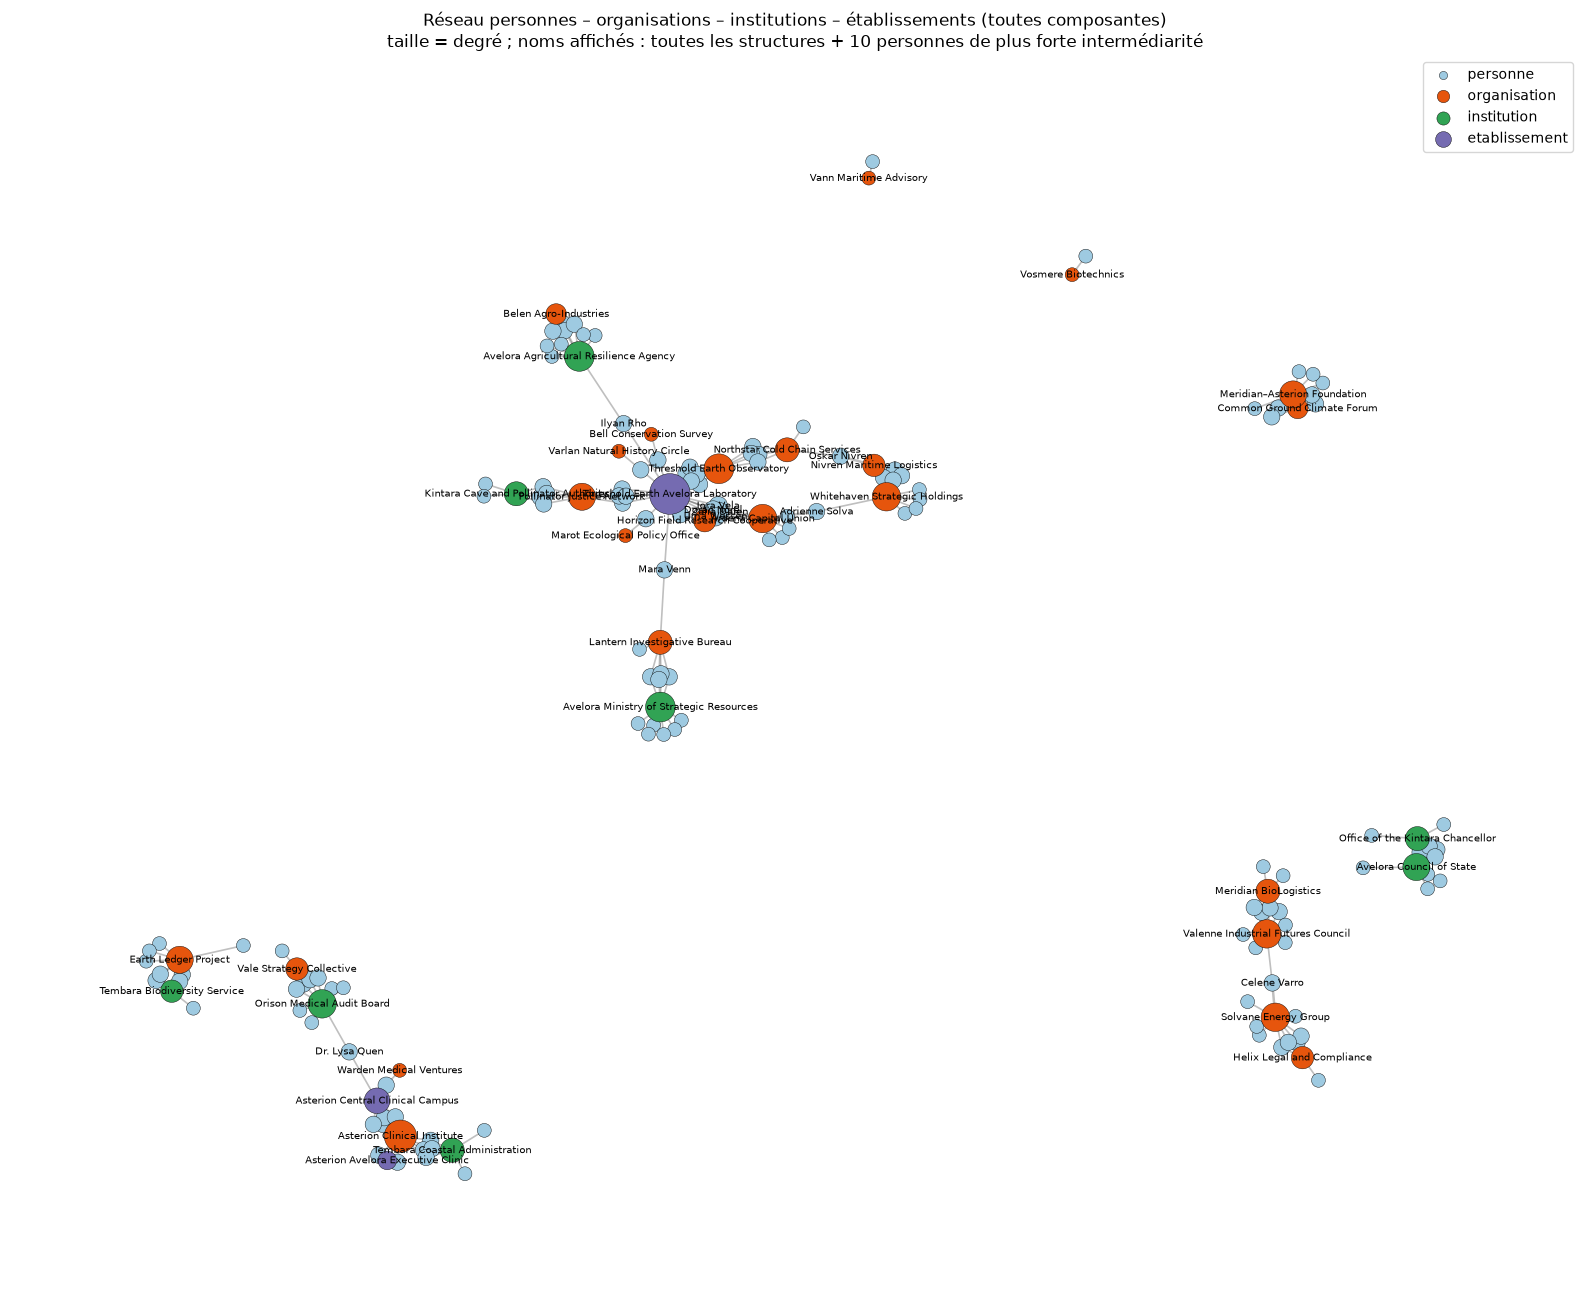

In [24]:
COLORS = {"personne": "#9ecae1", "organisation": "#e6550d", "institution": "#31a354", "etablissement": "#756bb1"}
# seed fixe pour obtenir toujours la meme disposition
pos = nx.spring_layout(G, seed=7, k=0.3, iterations=300)

fig, ax = plt.subplots(figsize=(16, 13))
widths = []
for u, v in G.edges:
    widths.append(0.6 + 0.6 * G[u][v]["weight"])
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25, width=widths)

for kind in COLORS:
    nodes = []
    sizes = []
    for node in G:
        if (G.nodes[node]["kind"] == kind):
            nodes.append(node)
            # la taille du point grandit avec le nombre de voisins
            sizes.append(60 + 40 * G.degree(node))
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=COLORS[kind], node_size=sizes, ax=ax,
                           label=kind, edgecolors="black", linewidths=0.3)

# afficher le nom de toutes les structures et des 10 personnes qui font le plus le lien
top_people = people.nlargest(10, "intermédiarité").index
labels = {}
for node in G:
    if (G.nodes[node]["kind"] != "personne" or node in top_people):
        labels[node] = G.nodes[node]["label"]
nx.draw_networkx_labels(G, pos, labels=labels, font_size=7, ax=ax)

ax.set_title("Réseau personnes – organisations – institutions – établissements (toutes composantes)\n"
             "taille = degré ; noms affichés : toutes les structures + 10 personnes de plus forte intermédiarité")
ax.legend(scatterpoints=1, markerscale=0.5)
ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "graphe_registres.png", dpi=150)
plt.show()

**Lecture du graphe.**

- Le réseau est **fragmenté** : 8 composantes. La plus grande (80 nœuds) regroupe l'écosystème écologie / agriculture / activisme d'Avelora et de Kintara. Son centre est l'établissement **Threshold Earth Avelora Laboratory** (degré 20, intermédiarité maximale 0,17), auquel sont rattachées presque toutes les licences environnementales et de recherche.
- Le pôle **médical** forme une composante séparée (30 nœuds) : Asterion Clinical Institute, ses deux établissements, l'**Orison Medical Audit Board**, la Tembara Coastal Administration, Vale Strategy Collective et Warden Medical Ventures. L'organisme d'audit médical est relié à l'établissement qu'il devrait contrôler par **Dr. Lysa Quen**, à la fois *Senior medical auditor* (nomination publique depuis 1995) et médecin rattaché à l'Asterion Central Clinical Campus.
- Le pôle **logistique / industrie** (Meridian BioLogistics, Valenne Industrial Futures Council, Solvane Energy Group, Helix Legal) forme une troisième composante. Il est relié au lobby industriel par d'anciens cadres (Vera Faron, Nora Essen, Alina Istra) et par **Celene Varro** (PDG de Solvane et membre du conseil industriel).
- Les personnes de plus forte intermédiarité sont des **passeurs** : **Mara Venn** (« ancienne employée de la recherche-logistique et source indépendante ») relie Lantern Investigative Bureau au laboratoire Threshold Earth, **Ilyan Rho** relie l'agence agricole au laboratoire, et **Adrienne Solva** relie Ardena Capital Union à Whitehaven Strategic Holdings.
- Vann Maritime Advisory et Vosmere Biotechnics sont **isolées** (un seul déclarant chacune) : rien dans les registres ne les relie au reste. Le lien éventuel vient d'autres sources (§6, §7).

## 4. Étudier les nominations et les départs

On rassemble mandats privés (`officer_filings`) et nominations publiques (`public_appointments`) dans une table unique de **postes** rattachés aux identités résolues. Un poste sans date de fin est considéré en cours jusqu'à la date de référence `2025-03-31` (dernière date de dépôt dans `registered_entities`). Les postes à dates incohérentes (§1) sont exclus des calculs de durée et de chevauchement.

In [25]:
# date du dernier depot connu : sert de "aujourd'hui" pour les postes en cours
REF_DATE = clean["entities"]["last_filing_date"].max()
print("Date de référence :", REF_DATE.date())

entity_name = entities.set_index("registration_number")["legal_name"]

rows = []
for r in officers.itertuples():
    rows.append({
        "person_id": pid[("officer_filings", r.filing_id)],
        "record_id": r.filing_id,
        "type": "mandat privé",
        "structure": entity_name[r.registration_number],
        "poste": r.role_title,
        "debut": r.appointment_date,
        "fin": r.cessation_date,
        "motif_depart": np.nan,
        "date_incoherente": r.date_incoherente
    })
for r in appointments.itertuples():
    rows.append({
        "person_id": pid[("public_appointments", r.appointment_record_id)],
        "record_id": r.appointment_record_id,
        "type": "nomination publique",
        "structure": r.institution_name,
        "poste": r.office_title,
        "debut": r.appointment_start,
        "fin": r.appointment_end,
        "motif_depart": r.departure_reason,
        "date_incoherente": r.date_incoherente
    })
posts = pd.DataFrame(rows)

posts["nom"] = posts["person_id"].map(persons_name)
posts["en_cours"] = posts["fin"].isna()
posts["fin_effective"] = posts["fin"].fillna(REF_DATE)
posts["duree_ans"] = ((posts["fin_effective"] - posts["debut"]).dt.days / 365.25).round(1)
# pas de duree pour les dates incoherentes
posts.loc[posts["date_incoherente"], "duree_ans"] = np.nan
posts["birth_min"] = posts["person_id"].map(persons["birth_min"])
posts["age_debut"] = posts["debut"].dt.year - posts["birth_min"]
print(posts["type"].value_counts().to_string())

Date de référence : 2025-03-31
type
mandat privé           135
nomination publique     62


### 4.1 Cumul de postes

In [26]:
rows = []
for person_id, group in posts.groupby("person_id"):
    n_private = int((group["type"] == "mandat privé").sum())
    n_public = int((group["type"] == "nomination publique").sum())
    rows.append({
        "person_id": person_id,
        "nom": group["nom"].iloc[0],
        "postes": len(group),
        "structures": group["structure"].nunique(),
        "mandats_prives": n_private,
        "nominations_publiques": n_public,
        "public_et_prive": (n_private > 0 and n_public > 0)
    })
cumul = pd.DataFrame(rows).set_index("person_id")

print("Personnes avec ≥ 2 postes :", int((cumul["postes"] >= 2).sum()))
print("Personnes à la fois dans le privé et dans le public :", int(cumul["public_et_prive"].sum()))
cumul.sort_values(["postes", "structures"], ascending=False).head(15)

Personnes avec ≥ 2 postes : 56
Personnes à la fois dans le privé et dans le public : 24


,nom,postes,structures,mandats_prives,nominations_publiques,public_et_prive
person_id,,,,,,
PER-015,Celene Varro,3,2,3,0,False
PER-016,Oskar Nivren,3,2,3,0,False
PER-017,Adrienne Solva,3,2,3,0,False
PER-018,Rayan Belen,3,2,2,1,True
PER-110,Elira Vaun,3,1,0,3,False
PER-022,Nora Essen,2,2,2,0,False
PER-024,Varen Valek,2,2,2,0,False
PER-026,Liora Maren,2,2,1,1,True
PER-027,Calen Uren,2,2,1,1,True


### 4.2 Chevauchements de postes

Deux postes d'une même personne se chevauchent si `début_1 < fin_2` et `début_2 < fin_1`. On distingue les chevauchements **dans la même structure** (promotion ou cumul interne, souvent anodin) et **entre structures différentes**, en particulier **public ↔ privé** (risque de conflit d'intérêts).

In [27]:
def period_text(post):
    """
    Periode d'un poste sous la forme "AAAA-MM→AAAA-MM" ou "AAAA-MM→en cours".
    """
    if (post.en_cours):
        return f"{post.debut:%Y-%m}→en cours"
    return f"{post.debut:%Y-%m}→{post.fin:%Y-%m}"


def overlap_category(a, b):
    """
    Classer un chevauchement selon le type et la structure des deux postes.
    """
    if (a.type != b.type):
        return "public ↔ privé"
    if (a.structure == b.structure):
        return "même structure"
    return f"{a.type} ×2, structures différentes"


valid = posts[~posts["date_incoherente"]]
overlaps = []
for person_id, group in valid.groupby("person_id"):
    for a, b in combinations(group.itertuples(), 2):
        # la periode commune va du debut le plus tardif a la fin la plus precoce
        start = max(a.debut, b.debut)
        end = min(a.fin_effective, b.fin_effective)
        if (start < end):
            overlaps.append({
                "person_id": person_id,
                "nom": a.nom,
                "poste_1": f"{a.poste} @ {a.structure}",
                "periode_1": period_text(a),
                "poste_2": f"{b.poste} @ {b.structure}",
                "periode_2": period_text(b),
                "chevauchement_ans": round((end - start).days / 365.25, 1),
                "categorie": overlap_category(a, b)
            })
overlaps = pd.DataFrame(overlaps).sort_values("chevauchement_ans", ascending=False)
print(overlaps["categorie"].value_counts().to_string())
overlaps[overlaps["categorie"] != "même structure"]

categorie
même structure                             6
mandat privé ×2, structures différentes    3
public ↔ privé                             1


,person_id,nom,poste_1,periode_1,poste_2,periode_2,chevauchement_ans,categorie
2,PER-016,Oskar Nivren,Executive chair of Nivren Maritime Logistics @ Nivren Ma...,1973-01→en cours,Regional logistics director @ Northstar Cold Chain Services,1973-03→1986-12,13.8,"mandat privé ×2, structures différentes"
7,PER-018,Rayan Belen,Chair of Belen Agro-Industries @ Belen Agro-Industries,1981-01→en cours,Agricultural programme director @ Avelora Agricultural R...,1981-01→1992-12,12.0,public ↔ privé
0,PER-015,Celene Varro,Chief executive of Solvane Energy Group @ Solvane Energy...,1977-01→en cours,Industry council member @ Valenne Industrial Futures Cou...,1977-05→1987-12,10.7,"mandat privé ×2, structures différentes"
4,PER-017,Adrienne Solva,Executive director of Ardena Capital Union @ Ardena Capi...,1987-01→en cours,Investment director @ Whitehaven Strategic Holdings,1987-09→1997-12,10.3,"mandat privé ×2, structures différentes"


In [28]:
overlaps[overlaps["categorie"] == "même structure"]

,person_id,nom,poste_1,periode_1,poste_2,periode_2,chevauchement_ans,categorie
9,PER-110,Elira Vaun,Retired political intermediary and former council presid...,1965-01→2021-09,Council president @ Avelora Council of State,1980-01→1998-12,19.0,même structure
8,PER-110,Elira Vaun,Retired political intermediary and former council presid...,1965-01→2021-09,State council secretary @ Avelora Council of State,1965-05→1979-12,14.7,même structure
3,PER-016,Oskar Nivren,Executive chair of Nivren Maritime Logistics @ Nivren Ma...,1973-01→en cours,Chief operating officer @ Nivren Maritime Logistics,1987-01→1998-12,12.0,même structure
5,PER-017,Adrienne Solva,Executive director of Ardena Capital Union @ Ardena Capi...,1987-01→en cours,Executive committee member @ Ardena Capital Union,1998-01→2008-12,11.0,même structure
6,PER-018,Rayan Belen,Chair of Belen Agro-Industries @ Belen Agro-Industries,1981-01→en cours,Managing director @ Belen Agro-Industries,1993-01→2002-12,10.0,même structure
1,PER-015,Celene Varro,Chief executive of Solvane Energy Group @ Solvane Energy...,1977-01→en cours,Executive board member @ Solvane Energy Group,1988-01→1997-06,9.5,même structure


### 4.3 Départs rapides ou inhabituels

Signaux recherchés :

- **durée courte** : poste terminé en moins de 2 ans ;
- **motif de départ** différent de la simple transition (`deceased`, `retired`) ;
- **durée très longue** : poste encore en cours après plus de 40 ans ;
- **âge invraisemblable** : âge au début < 18 ans, ou personne encore en poste / licence encore active à plus de 100 ans ;
- **pivot public → privé** : départ d'une nomination publique suivi, dans les 2 ans, d'un mandat privé (ou l'inverse).

In [29]:
rows = []
for r in posts.itertuples():
    # un meme poste peut declencher plusieurs signaux
    found = []
    if (not r.en_cours and r.duree_ans < 2):
        found.append("durée < 2 ans")
    if (r.motif_depart in ["deceased", "retired"]):
        found.append("départ : " + r.motif_depart)
    if (r.en_cours and r.duree_ans > 40):
        found.append("en cours depuis > 40 ans")
    if (r.age_debut < 18):
        found.append("âge au début < 18")
    for signal in found:
        rows.append({
            "signal": signal, "nom": r.nom, "type": r.type, "poste": r.poste, "structure": r.structure,
            "debut": r.debut, "fin": r.fin, "duree_ans": r.duree_ans,
            "birth_min": r.birth_min, "age_debut": r.age_debut
        })
signals = pd.DataFrame(rows)
signals.sort_values(["signal", "debut"])

,signal,nom,type,poste,structure,debut,fin,duree_ans,birth_min,age_debut
9,durée < 2 ans,Miran Lorin,nomination publique,Regional adviser,Orison Medical Audit Board,2011-01-01,2011-12-31,1.0,1987.0,24.0
7,départ : deceased,Elira Vaun,nomination publique,Retired political intermediary and former council president,Avelora Council of State,1965-01-01,2021-09-18,56.7,1935.0,30.0
10,départ : retired,Orin Jaren,nomination publique,Deputy minister,Avelora Ministry of Strategic Resources,1992-01-01,2003-12-31,12.0,1961.0,31.0
8,départ : retired,Xara Lask,nomination publique,Senior executive-office official,Office of the Kintara Chancellor,1997-01-01,2018-12-31,22.0,1968.0,29.0
12,départ : retired,Sena Grell,nomination publique,Regional administrative director,Tembara Coastal Administration,2003-01-01,2013-12-31,11.0,1970.0,33.0
1,en cours depuis > 40 ans,Oskar Nivren,mandat privé,Executive chair of Nivren Maritime Logistics,Nivren Maritime Logistics,1973-01-01,NaT,52.2,1946.0,27.0
6,en cours depuis > 40 ans,Mirek Talven,nomination publique,Regional governor in the Tembara Commonwealth,Tembara Coastal Administration,1974-01-01,NaT,51.2,1942.0,32.0
0,en cours depuis > 40 ans,Celene Varro,mandat privé,Chief executive of Solvane Energy Group,Solvane Energy Group,1977-01-01,NaT,48.2,1950.0,27.0
4,en cours depuis > 40 ans,Leora Kassen,nomination publique,Head of government of Kintara Republic,Office of the Kintara Chancellor,1978-01-01,NaT,47.2,1947.0,31.0
3,en cours depuis > 40 ans,Bran Grell,mandat privé,Maritime operations executive,Nivren Maritime Logistics,1980-01-01,NaT,45.2,1949.0,31.0


In [30]:
transitions = []
finished = valid[valid["fin"].notna()]
for person_id, group in finished.groupby("person_id"):
    for a in group.itertuples():
        # chercher un poste de l'autre type qui commence au plus 2 ans apres la fin
        for b in valid[valid["person_id"] == person_id].itertuples():
            if (b.type == a.type):
                continue
            too_early = b.debut < a.fin - pd.DateOffset(days=31)
            too_late = b.debut > a.fin + pd.DateOffset(years=2)
            if (not too_early and not too_late):
                transitions.append({
                    "nom": a.nom,
                    "quitte": f"{a.poste} @ {a.structure}",
                    "fin": a.fin.date(),
                    "rejoint": f"{b.poste} @ {b.structure}",
                    "debut": b.debut.date(),
                    "sens": f"{a.type} → {b.type}"
                })
pd.DataFrame(transitions)

,nom,quitte,fin,rejoint,debut,sens
0,Rayan Belen,Agricultural programme director @ Avelora Agricultural R...,1992-12-31,Managing director @ Belen Agro-Industries,1993-01-01,nomination publique → mandat privé
1,Liora Maren,Deputy director @ Pollinator Justice Network,2016-12-31,Wildlife programme officer @ Kintara Cave and Pollinator...,2017-01-01,mandat privé → nomination publique
2,Nora Yorin,Programme manager @ Orison Medical Audit Board,2018-12-31,Policy consultant @ Vale Strategy Collective,2019-01-01,nomination publique → mandat privé
3,Yorin Serin,Deputy director @ Avelora Ministry of Strategic Resources,1989-12-31,Investigative reporter @ Lantern Investigative Bureau,1990-01-01,nomination publique → mandat privé
4,Faris Quell,Regional adviser @ Avelora Agricultural Resilience Agency,2007-12-31,Agricultural operations director @ Belen Agro-Industries,2008-01-01,nomination publique → mandat privé
5,Petra Grell,Operations manager @ Pollinator Justice Network,2004-12-31,Wildlife programme officer @ Kintara Cave and Pollinator...,2005-01-01,mandat privé → nomination publique
6,Doran Maren,Deputy director @ Earth Ledger Project,1993-12-31,Biodiversity programme officer @ Tembara Biodiversity Se...,1994-01-01,mandat privé → nomination publique
7,Miran Lorin,Regional adviser @ Orison Medical Audit Board,2011-12-31,Policy consultant @ Vale Strategy Collective,2012-01-01,nomination publique → mandat privé
8,Xara Orell,Regional adviser @ Avelora Ministry of Strategic Resources,2011-12-31,Investigative reporter @ Lantern Investigative Bureau,2012-01-01,nomination publique → mandat privé
9,Orin Kassen,Programme manager @ Avelora Agricultural Resilience Agency,2007-12-31,Agricultural operations director @ Belen Agro-Industries,2008-01-01,nomination publique → mandat privé


### 4.4 Chronologie des mandats et des licences

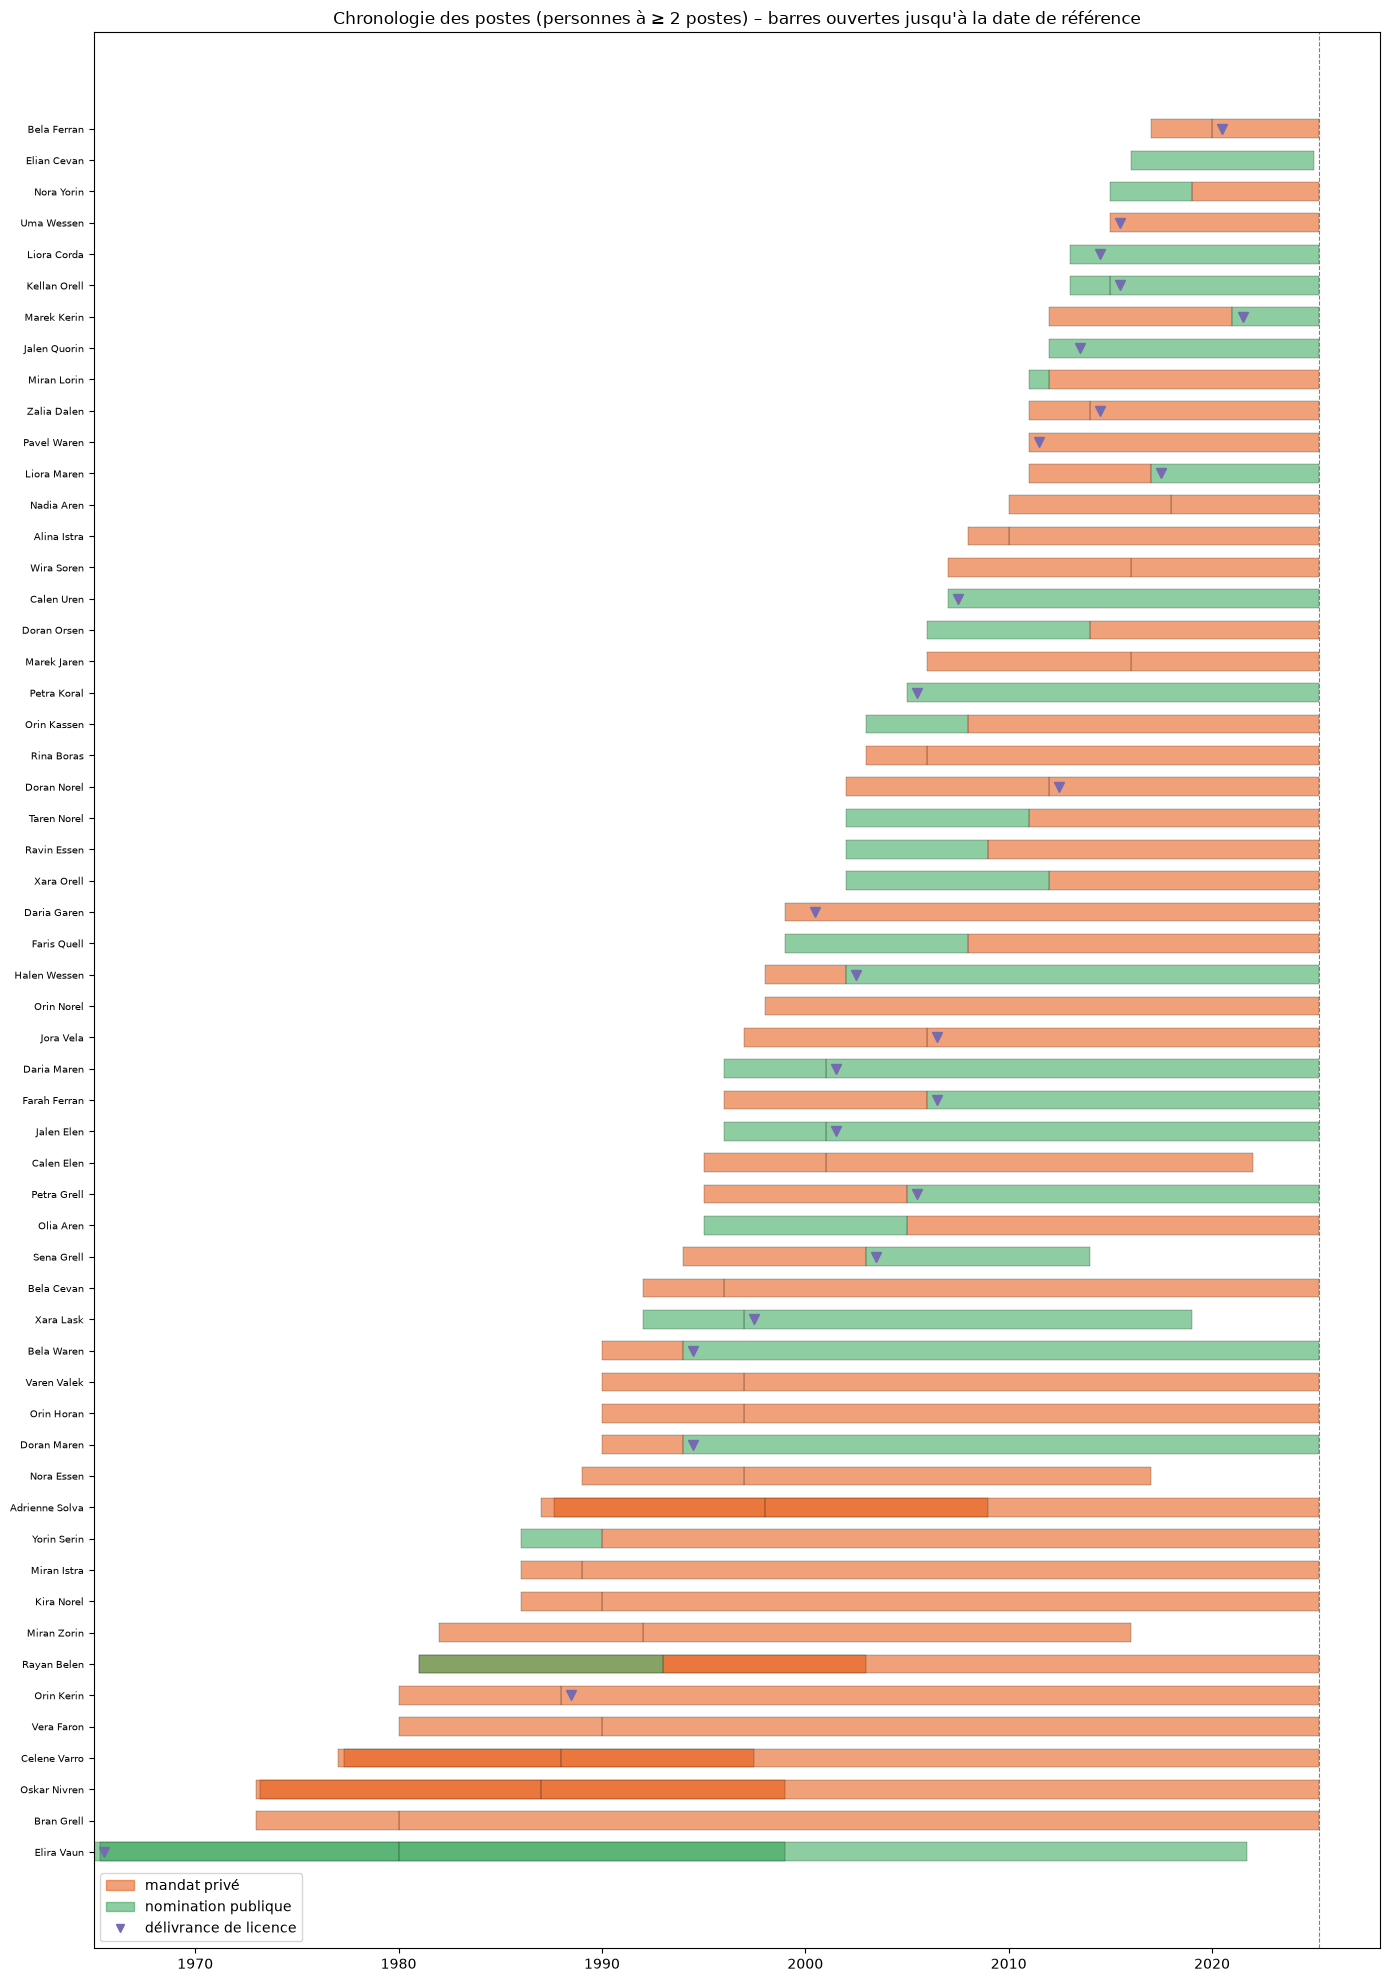

In [31]:
licence_person = []
for license_number in professionals["license_number"]:
    licence_person.append(pid[("licensed_professionals", license_number)])
licences = professionals.copy()
licences["person_id"] = licence_person

# personnes avec au moins 2 postes, ou presentes dans le public et le prive
selected = cumul[(cumul["postes"] >= 2) | cumul["public_et_prive"]].index
timeline = posts[posts["person_id"].isin(selected) & ~posts["date_incoherente"]]
order = timeline.groupby("person_id")["debut"].min().sort_values().index
ypos = {}
for i in range(len(order)):
    ypos[order[i]] = i

fig, ax = plt.subplots(figsize=(14, 0.32 * len(order) + 2))
colors = {"mandat privé": "#e6550d", "nomination publique": "#31a354"}
for r in timeline.itertuples():
    duration = (r.fin_effective - r.debut).days
    ax.barh(ypos[r.person_id], duration, left=r.debut, height=0.6,
            color=colors[r.type], alpha=0.55, edgecolor="black", linewidth=0.3)
for r in licences.itertuples():
    if (r.person_id in ypos):
        ax.plot(r.license_issue_date, ypos[r.person_id], marker="v", color="#756bb1", markersize=7)

names_in_order = []
for person_id in order:
    names_in_order.append(persons_name[person_id])
ax.set_yticks(range(len(order)))
ax.set_yticklabels(names_in_order, fontsize=7)
ax.axvline(REF_DATE, color="grey", linestyle="--", linewidth=0.8)

handles = []
for kind in colors:
    handles.append(plt.Rectangle((0, 0), 1, 1, color=colors[kind], alpha=0.55))
handles.append(plt.Line2D([], [], marker="v", color="#756bb1", linestyle=""))
ax.legend(handles, ["mandat privé", "nomination publique", "délivrance de licence"], loc="lower left")
ax.set_title("Chronologie des postes (personnes à ≥ 2 postes) – barres ouvertes jusqu'à la date de référence")
plt.tight_layout()
plt.savefig(OUT / "chronologie_mandats.png", dpi=150)
plt.show()

**Résultats sur les nominations et les départs.**

1. **Cumuls** : 56 personnes ont au moins 2 postes et 24 apparaissent à la fois dans le privé et dans le public. Les seuls cumuls simultanés entre structures différentes concernent des dirigeants historiques :
   - **Rayan Belen**, président de Belen Agro-Industries depuis 1981 et en même temps directeur du programme agricole de l'Avelora Agricultural Resilience Agency (1981-1992). C'est le seul chevauchement public ↔ privé (12 ans), donc un risque clair de conflit d'intérêts ;
   - **Celene Varro** (Solvane + conseil industriel) et **Adrienne Solva** (Ardena + Whitehaven) ;
   - **Oskar Nivren**, président de Nivren Maritime Logistics et en même temps directeur régional d'un autre transporteur, Northstar Cold Chain Services (1973-1986).
2. **Allers-retours public ↔ privé** : 19 transitions se font **du jour au lendemain** (fin au 31/12, début au 01/01). Elles forment des **filières régulières** :
   - Avelora Agricultural Resilience Agency → Belen Agro-Industries (4 personnes) ;
   - Orison Medical Audit Board → Vale Strategy Collective (4) ;
   - Avelora Ministry of Strategic Resources → Lantern Investigative Bureau (3) ;
   - Pollinator Justice Network → Kintara Cave and Pollinator Authority (4) ;
   - Earth Ledger Project → Tembara Biodiversity Service (3) ;
   - Asterion Clinical Institute → Tembara Coastal Administration (Sena Grell).

   Le régulateur agricole alimente l'agro-industriel qu'il encadre, et l'auditeur médical alimente le cabinet de conseil de Jacob Vale.
3. **Mandats très longs** : plusieurs dirigeants politiques sont en poste depuis plus de 40 ans sans date de fin : **Mirek Talven** (gouverneur depuis 1974), **Leora Kassen** (cheffe de gouvernement depuis 1978), **Zalia Maren** (vice-ministre depuis 1980), **Tavian Serat** (ministre depuis 1984). **Elira Vaun** est restée au Conseil d'État de 1965 à son décès en 2021. Côté privé, Oskar Nivren, Celene Varro et Rayan Belen dirigent leur entreprise depuis 1973-1981.
4. **Départs courts** : un seul mandat dure moins de 2 ans (Miran Lorin à l'Orison Medical Audit Board, 2011), suivi d'un départ immédiat vers Vale Strategy Collective.
5. **Dates incohérentes (9 dépôts)** : chaque fois, la cessation précède la nomination (de 1 jour à 1 an). Pour 3 d'entre eux (Liora Corda, Jalen Quorin, Petra Koral : *Regional adviser* chez Asterion), la personne occupe déjà, ou commence la même année, une nomination publique de *Regional administrative director* à la Tembara Coastal Administration. Il pourrait donc s'agir de mandats déclarés mais jamais exercés. C'est une hypothèse non vérifiable ici.

### 4.5 Plausibilité des licences

`license_expiry_date` étant toujours vide, on contrôle la validité par l'**ancienneté** : une licence délivrée il y a plus de 60 ans et toujours `active`, ou détenue par une personne qui aurait plus de 100 ans, est invraisemblable. On croise avec l'année de naissance connue côté mandats et on signale les licences délivrées après la date de référence.

In [32]:
lic = licences.copy()
lic["anciennete_ans"] = ((REF_DATE - lic["license_issue_date"]).dt.days / 365.25).round(0)
lic["birth_min"] = lic["person_id"].map(persons["birth_min"])
lic["age_ref"] = REF_DATE.year - lic["birth_min"]
lic["apres_ref"] = lic["license_issue_date"] > REF_DATE

fac_start = clean["facilities"].set_index("facility_license_number")["license_start"]
lic["etab_ouvert_apres_licence"] = lic["primary_facility_license"].map(fac_start) > lic["license_issue_date"]
print("Licences rattachées à un établissement principal ouvert après leur délivrance :",
      int(lic["etab_ouvert_apres_licence"].sum()), "/", int(lic["primary_facility_license"].notna().sum()))

too_old = lic["anciennete_ans"] > 60
too_aged = lic["age_ref"] > 100
suspicious_lic = lic[too_old | too_aged | lic["apres_ref"]]
suspicious_lic[["license_number", "professional_name", "profession", "specialty", "license_issue_date",
                "license_status", "primary_facility_license", "etab_ouvert_apres_licence",
                "anciennete_ans", "birth_min", "age_ref", "apres_ref"]]

Licences rattachées à un établissement principal ouvert après leur délivrance : 22 / 27


,license_number,professional_name,profession,specialty,license_issue_date,license_status,primary_facility_license,etab_ouvert_apres_licence,anciennete_ans,birth_min,age_ref,apres_ref
0,LIC-VLN-MED-1001,Emil Warden,physician,cardiology,1895-07-01,active,FAC-VLN-101,True,130.0,1871.0,154.0,False
5,LIC-VLN-MED-1006,Farah Havel,physician,occupational medicine,2026-07-01,active,FAC-AVL-201,False,-1.0,1994.0,31.0,True
6,LIC-KNT-RES-1007,J. Varlan,research professional,ecological analytics,1886-07-01,active,FAC-AVL-301,True,139.0,1862.0,163.0,False
7,LIC-AVL-RES-1008,Jonah Bell,research professional,public policy research,1924-07-01,active,FAC-AVL-301,True,101.0,1900.0,125.0,False


Toutes les licences restent `active`, y compris celles de personnes nées au XIXe siècle : **J. Varlan** (délivrée en 1886, il aurait 163 ans), **Jonah Bell** (1924, 125 ans) et **Emil Warden** (1895, 154 ans). À l'inverse, la licence de **Farah Havel** est datée du 2026-07-01, après la date de référence. Le registre ne gère donc pas la fin de validité des licences. Le contrôle suivant (§5) vérifie si ces licences sont réellement utilisées.

22 des 27 licences sont rattachées à un établissement ouvert *après* leur délivrance. On l'interprète comme une affectation **actuelle** (mise à jour du rattachement) plutôt que comme une anomalie.

## 5. Relier les registres à la santé

Jointures par clé exacte (pas de rapprochement par nom) :

- `clinical_encounters.attending_license_number` → `licensed_professionals.license_number`
- `clinical_encounters.facility_license_number` → `licensed_facilities.facility_license_number`
- idem pour `clinical_procedures` (`performing_license_number`, `performing_facility_license`).

Contrôle préalable : toutes les clés étrangères doivent exister dans le registre, et une jointure *many-to-one* ne doit pas multiplier les lignes.

In [33]:
enc = clean["encounters"]
proc = clean["procedures"]

# chaque cle etrangere doit exister dans le registre correspondant
checks = [
    ("encounters.attending_license_number", enc["attending_license_number"], professionals["license_number"]),
    ("encounters.facility_license_number", enc["facility_license_number"], facilities["facility_license_number"]),
    ("procedures.performing_license_number", proc["performing_license_number"], professionals["license_number"]),
    ("procedures.performing_facility_license", proc["performing_facility_license"], facilities["facility_license_number"]),
]
rows = []
for label, keys, reference in checks:
    found = keys.isin(reference)
    rows.append({"jointure": label, "clés trouvées": int(found.sum()), "clés absentes": int((~found).sum())})
pd.DataFrame(rows).set_index("jointure")

,clés trouvées,clés absentes
jointure,,
encounters.attending_license_number,1069,0
encounters.facility_license_number,1069,0
procedures.performing_license_number,311,0
procedures.performing_facility_license,311,0


In [34]:
# many_to_one : une licence par ligne cote registre, donc pas de lignes en plus
enc_p = enc.merge(professionals, left_on="attending_license_number", right_on="license_number",
                  how="left", validate="many_to_one")
assert len(enc_p) == len(enc)
proc_p = proc.merge(professionals, left_on="performing_license_number", right_on="license_number",
                    how="left", validate="many_to_one")
assert len(proc_p) == len(proc)

rows = []
for license_number, group in enc_p.groupby("attending_license_number"):
    secret = group["confidentiality_class"].isin(["confidential", "restricted"])
    # rencontres signees avant meme que la licence existe
    before_licence = group["encounter_start"] < group["license_issue_date"]
    rows.append({
        "attending_license_number": license_number,
        "praticien": group["professional_name"].iloc[0],
        "specialite": group["specialty"].iloc[0],
        "licence_delivree": group["license_issue_date"].iloc[0],
        "etab_principal": group["primary_facility_license"].iloc[0],
        "rencontres": len(group),
        "patients": group["patient_number"].nunique(),
        "premiere": group["encounter_start"].min(),
        "derniere": group["encounter_start"].max(),
        "part_confidentiel_restreint": round(secret.mean(), 2),
        "rencontres_avant_licence": int(before_licence.sum())
    })
vol = pd.DataFrame(rows).set_index("attending_license_number")

vol["procedures"] = proc_p.groupby("performing_license_number").size()
mrp = proc_p[proc_p["procedure_code"] == "MRP-42"]
vol["MRP-42"] = mrp.groupby("performing_license_number").size()
vol["MRP-42"] = vol["MRP-42"].fillna(0).astype(int)

births = []
for license_number in vol.index:
    person_id = pid[("licensed_professionals", license_number)]
    births.append(persons.loc[person_id, "birth_min"])
vol["birth_min"] = births
vol["age_derniere_rencontre"] = vol["derniere"].dt.year - vol["birth_min"]
vol = vol[["praticien", "specialite", "licence_delivree", "etab_principal", "rencontres", "patients",
           "premiere", "derniere", "part_confidentiel_restreint", "procedures", "MRP-42",
           "rencontres_avant_licence", "birth_min", "age_derniere_rencontre"]]
vol.sort_values("rencontres", ascending=False)

,praticien,specialite,licence_delivree,etab_principal,rencontres,patients,premiere,derniere,part_confidentiel_restreint,procedures,MRP-42,rencontres_avant_licence,birth_min,age_derniere_rencontre
attending_license_number,,,,,,,,,,,,,,
LIC-VLN-MED-1002,Dr. Naima Orrel,preventive medicine,2002-07-01,FAC-VLN-101,162,112,2014-07-18 08:30:00,2025-06-20 14:15:00,0.56,67,36,0,1978.0,47.0
LIC-VLN-MED-1001,Emil Warden,cardiology,1895-07-01,FAC-VLN-101,147,118,2015-09-21 09:15:00,2025-06-20 13:15:00,0.51,35,1,0,1871.0,154.0
LIC-VLN-RES-1016,Daria Zaven,general medicine,1990-07-01,FAC-VLN-101,140,112,2017-01-26 09:15:00,2026-01-11 14:15:00,0.43,44,3,0,1950.0,76.0
LIC-VLN-MED-1006,Farah Havel,occupational medicine,2026-07-01,FAC-AVL-201,136,110,2014-02-18 09:15:00,2025-09-11 14:15:00,0.42,33,4,136,1994.0,31.0
LIC-VLN-MED-1003,Dr. Corin Hale,cardiac imaging,2002-07-01,FAC-AVL-201,122,99,2017-02-05 09:15:00,2025-06-21 14:15:00,0.44,31,1,0,1974.0,51.0
LIC-VLN-MED-1004,Dr. Lysa Quen,medical audit,1995-07-01,FAC-VLN-101,121,98,2014-08-15 10:15:00,2025-06-20 13:15:00,0.44,32,3,0,1968.0,57.0
LIC-VLN-RES-1044,Ravin Palen,clinical physiology,1995-07-01,FAC-VLN-101,121,99,2016-03-22 10:15:00,2025-06-20 13:15:00,0.36,31,2,0,1963.0,62.0
LIC-VLN-MED-1005,Faris Uren,cardiology,1986-07-01,FAC-VLN-101,120,96,2015-04-13 09:15:00,2025-06-20 13:15:00,0.44,38,0,0,1961.0,64.0


In [35]:
in_encounters = professionals["license_number"].isin(enc["attending_license_number"])
in_procedures = professionals["license_number"].isin(proc["performing_license_number"])
health_people = in_encounters | in_procedures
print(f"Professionnels licenciés présents dans les données de santé : {health_people.sum()} / {len(professionals)}")
print("Professions :", professionals.loc[health_people, "profession"].value_counts().to_dict())

fac_by_id = facilities.set_index("facility_license_number")
rows = []
for facility, group in enc.groupby("facility_license_number"):
    start = fac_by_id.loc[facility, "license_start"]
    rows.append({
        "facility_license_number": facility,
        "rencontres": len(group),
        "patients": group["patient_number"].nunique(),
        "rencontres_avant_licence": int((group["encounter_start"] < start).sum())
    })
counts = pd.DataFrame(rows).set_index("facility_license_number")
counts["procedures"] = proc.groupby("performing_facility_license").size()

fac_vol = fac_by_id[["facility_name", "facility_category", "operating_organization_registration", "license_start"]]
fac_vol = fac_vol.join(counts[["rencontres", "patients", "procedures", "rencontres_avant_licence"]])
fac_vol["operateur"] = fac_vol["operating_organization_registration"].map(entity_name)
fac_vol

Professionnels licenciés présents dans les données de santé : 8 / 53
Professions : {'physician': 8}


,facility_name,facility_category,operating_organization_registration,license_start,rencontres,patients,procedures,rencontres_avant_licence,operateur
facility_license_number,,,,,,,,,
FAC-VLN-101,Asterion Central Clinical Campus,research_hospital,REG-VLN-01002,2001-02-01,659,150,179,0,Asterion Clinical Institute
FAC-AVL-201,Asterion Avelora Executive Clinic,private_clinic,REG-VLN-01002,2008-05-15,294,64,101,0,Asterion Clinical Institute
FAC-AVL-301,Threshold Earth Avelora Laboratory,research_laboratory,REG-AVL-01007,2012-01-18,116,26,31,0,Threshold Earth Observatory


In [36]:
# les praticiens exercent-ils seulement dans leur etablissement principal declare ?
pd.crosstab(enc_p["professional_name"], enc_p["facility_license_number"], margins=True)

facility_license_number,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101,All
professional_name,,,,
Daria Zaven,31,14,95,140
Dr. Corin Hale,32,9,81,122
Dr. Lysa Quen,32,17,72,121
Dr. Naima Orrel,46,13,103,162
Emil Warden,34,19,94,147
Farah Havel,40,14,82,136
Faris Uren,43,17,60,120
Ravin Palen,36,13,72,121
All,294,116,659,1069


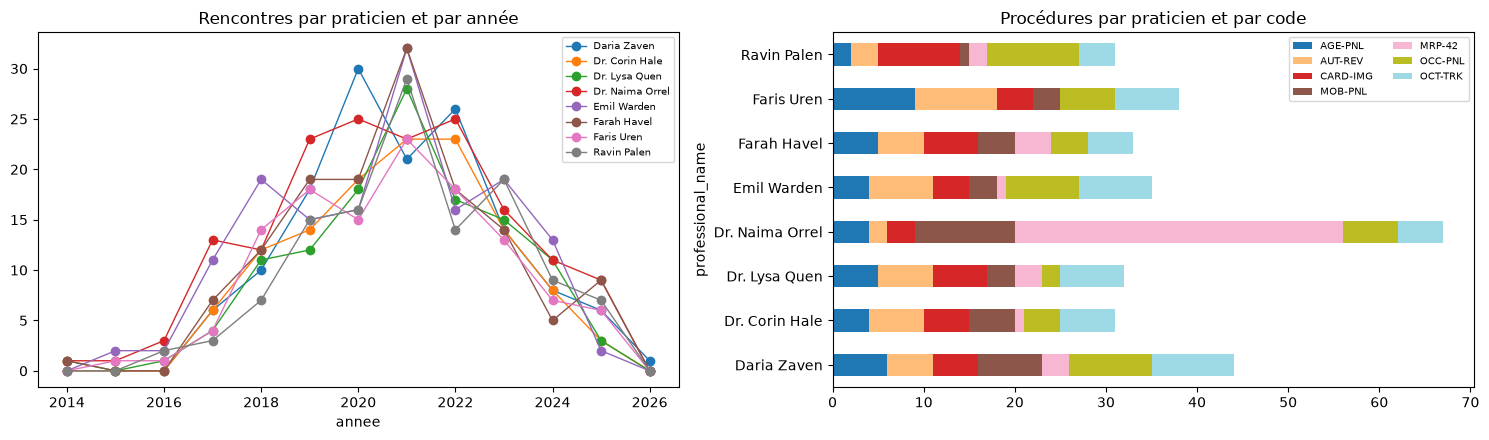

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

enc_p["annee"] = enc_p["encounter_start"].dt.year
yearly = enc_p.pivot_table(index="annee", columns="professional_name", values="encounter_number",
                           aggfunc="count").fillna(0)
yearly.plot(ax=axes[0], marker="o", linewidth=1)
axes[0].set_title("Rencontres par praticien et par année")
axes[0].legend(fontsize=7)

by_code = proc_p.pivot_table(index="professional_name", columns="procedure_code", values="procedure_record_id",
                             aggfunc="count").fillna(0)
by_code.plot(kind="barh", stacked=True, ax=axes[1], colormap="tab20")
axes[1].set_title("Procédures par praticien et par code")
axes[1].legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.savefig(OUT / "volumes_sante.png", dpi=150)
plt.show()

**Résultats santé.**

- Seuls **8 des 53** professionnels licenciés apparaissent dans les données cliniques, tous médecins. Toutes les clés de praticien et d'établissement existent dans le registre, et les jointures ne dupliquent aucune ligne.
- Les volumes sont proches entre praticiens (120 à 162 rencontres). Les rencontres se concentrent à l'Asterion Central Clinical Campus (659). Asterion exploite deux des trois établissements, soit 89 % des rencontres.
- **Licence d'Emil Warden (LIC-VLN-MED-1001)** : délivrée en 1895 à une personne née en 1871. Elle sert pourtant à signer **147 rencontres entre 2015 et 2025**, ce qui supposerait un praticien de 144 à 154 ans. Le fait est établi par une jointure exacte. Son interprétation reste ouverte : réutilisation d'une ancienne licence, usurpation d'identité ou continuité d'identité (§7).
- **Licence de Farah Havel (LIC-VLN-MED-1006)** : délivrée le **2026-07-01**, donc après chacune des 136 rencontres signées (2014-2025). Son mandat chez Asterion commence aussi en 2026. Des actes ont donc été signés sous un numéro de licence qui n'existait pas encore.
- **Dr. Naima Orrel**, directrice de recherche d'Asterion, réalise **36 des 50 actes MRP-42** (« Targeted metabolic resilience administration »), soit 72 %. Les autres praticiens en font entre 0 et 4. Ses rencontres et celles d'Emil Warden ont aussi la plus forte part de dossiers *confidential/restricted* (56 % et 51 %).
- Chaque praticien exerce dans les trois établissements, quel que soit son établissement principal déclaré. Le champ `primary_facility_license` décrit donc un rattachement administratif, pas le lieu réel d'exercice.

## 6. Relier les registres à la logistique

1. **Partenaires** : `erp_business_partners.external_registration_number` → `registered_entities.registration_number` (clé exacte), puis contrôle de cohérence du nom et des dates (un partenaire ne devrait pas être intégré après la dissolution de l'entité).
2. **Partenaires sans clé connue** : rapprochement approché du `partner_name` avec `legal_name`, pour repérer d'éventuelles organisations enregistrées sous une autre clé.
3. **Installations** : `erp_facilities` ↔ `licensed_facilities` (nom normalisé + distance entre coordonnées) et ↔ `registered_entities.registered_address` (une adresse d'organisation qui correspond à une installation logistique).

In [38]:
partners = clean["partners"]
erp_fac = clean["erp_facilities"]

has_key = partners["external_registration_number"].notna()
in_registry = partners["external_registration_number"].isin(entities["registration_number"])
print(f"Partenaires : {len(partners)} | avec numéro d'enregistrement : {has_key.sum()} "
      f"| trouvés dans le registre : {in_registry.sum()}")

# regarder le debut des numeros inconnus pour comprendre leur format
prefixes = {}
for number in partners.loc[has_key & ~in_registry, "external_registration_number"]:
    prefix = number[:9]
    prefixes[prefix] = prefixes.get(prefix, 0) + 1
print("Préfixes des numéros absents du registre :", pd.Series(prefixes).sort_values(ascending=False).to_dict())

with_key = partners[has_key]
pe = with_key.merge(entities, left_on="external_registration_number", right_on="registration_number",
                    how="inner", validate="one_to_one")
pe["meme_nom"] = pe["partner_name"].map(normalize_name) == pe["legal_name"].map(normalize_name)
# une entite dissoute ne devrait pas devenir partenaire apres sa dissolution
dissolved = pe["current_status"] == "dissolved"
pe["integre_apres_dissolution"] = dissolved & (pe["onboarding_date"] > pe["last_filing_date"])
pe["ecart_ans"] = ((pe["onboarding_date"] - pe["last_filing_date"]).dt.days / 365.25).round(0)
print("Noms identiques partenaire/registre :", pe["meme_nom"].all())

table = pe[["partner_code", "partner_name", "partner_role", "risk_class", "partner_status", "onboarding_date",
            "registration_number", "registered_entity_type", "current_status", "last_filing_date",
            "integre_apres_dissolution", "ecart_ans"]]
table.sort_values(["integre_apres_dissolution", "onboarding_date"], ascending=[False, True])

Partenaires : 80 | avec numéro d'enregistrement : 66 | trouvés dans le registre : 24
Préfixes des numéros absents du registre : {'REG-VLN-2': 13, 'REG-TMB-2': 9, 'REG-AVL-2': 8, 'REG-KNT-2': 6, 'REG-NDH-2': 6}
Noms identiques partenaire/registre : True


,partner_code,partner_name,partner_role,risk_class,partner_status,onboarding_date,registration_number,registered_entity_type,current_status,last_filing_date,integre_apres_dissolution,ecart_ans
4,BP-30013,Vann Maritime Advisory,service_partner,standard,inactive,2001-02-01,REG-NDH-01015,consulting_company,dissolved,1891-12-31,True,109.0
19,BP-30059,Bell Conservation Survey,customer,standard,inactive,2004-12-01,REG-AVL-01019,research_institute,dissolved,1966-12-31,True,38.0
7,BP-30022,Varlan Natural History Circle,customer,low,inactive,2008-11-01,REG-KNT-01018,research_institute,dissolved,1920-12-31,True,88.0
9,BP-30038,Vosmere Biotechnics,supplier_customer,standard,inactive,2009-03-01,REG-NDH-01017,biotechnology_company,dissolved,1994-12-31,True,14.0
1,BP-30005,Warden Medical Ventures,service_partner,standard,inactive,2013-06-01,REG-VLN-01016,investment_company,dissolved,1948-12-31,True,64.0
21,BP-30066,Belen Agro-Industries,supplier_customer,standard,active,2000-07-01,REG-KNT-01024,agricultural_company,active,2025-03-31,False,-25.0
6,BP-30021,Asterion Clinical Institute,customer,review,active,2003-10-01,REG-VLN-01002,research_institute,active,2025-03-31,False,-21.0
18,BP-30058,Marot Ecological Policy Office,service_partner,standard,inactive,2004-11-01,REG-VLN-01020,consulting_company,dissolved,2006-12-31,False,-2.0
16,BP-30047,Northstar Cold Chain Services,carrier,elevated,active,2006-12-01,REG-TMB-01003,logistics_company,active,2025-03-31,False,-18.0
20,BP-30062,Solvane Energy Group,customer,elevated,active,2007-03-01,REG-VLN-01021,energy_company,active,2025-03-31,False,-18.0


In [39]:
pd.crosstab(pe["current_status"], pe["risk_class"], margins=True)

risk_class,elevated,low,review,standard,All
current_status,,,,,
active,5,2,4,7,18
dissolved,0,1,0,5,6
All,5,3,4,12,24


In [40]:
unmatched = partners[~in_registry]
fuzzy = []
for r in unmatched.itertuples():
    for e in entities.itertuples():
        score = sim(normalize_name(r.partner_name), normalize_name(e.legal_name))
        if (score >= 0.7):
            fuzzy.append({
                "partner_code": r.partner_code,
                "partner_name": r.partner_name,
                "external_registration_number": r.external_registration_number,
                "legal_name": e.legal_name,
                "registration_number": e.registration_number,
                "sim": round(score, 2)
            })
print(f"Partenaires hors registre rapprochés par nom (≥ 0,7) : {len(fuzzy)}")
pd.DataFrame(fuzzy)

Partenaires hors registre rapprochés par nom (≥ 0,7) : 3


,partner_code,partner_name,external_registration_number,legal_name,registration_number,sim
0,BP-30026,Valenne Industrial Supply Consortium,REG-VLN-20040,Valenne Industrial Futures Council,REG-VLN-01005,0.71
1,BP-30029,Kestrel Conservation Services,REG-KNT-20014,Bell Conservation Survey,REG-AVL-01019,0.75
2,BP-30077,Velin Packaging Industries,REG-AVL-20021,Belen Agro-Industries,REG-KNT-01024,0.72


In [41]:
def haversine_km(lat1, lon1, lat2, lon2):
    """
    Distance en km entre deux points donnes en latitude/longitude.
    """
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    # 6371 km = rayon moyen de la Terre
    return 6371 * 2 * np.arcsin(np.sqrt(a))


partner_reg = partners.set_index("partner_code")["external_registration_number"]
rows = []
for f in erp_fac.itertuples():
    for lf in facilities.itertuples():
        score = sim(normalize_name(f.facility_name), normalize_name(lf.facility_name))
        if (score >= 0.8):
            distance = haversine_km(float(f.latitude), float(f.longitude), float(lf.latitude), float(lf.longitude))
            rows.append({
                "facility_code": f.facility_code,
                "erp_name": f.facility_name,
                "erp_category": f.facility_category,
                "facility_license_number": lf.facility_license_number,
                "registry_name": lf.facility_name,
                "sim_nom": round(score, 2),
                "distance_km": round(distance, 1),
                # operateur cote ERP, traduit en numero du registre
                "operateur_erp → reg": partner_reg.get(f.operating_partner_code),
                "operateur_registre": lf.operating_organization_registration
            })
fac_match = pd.DataFrame(rows)
fac_match["meme_operateur"] = fac_match["operateur_erp → reg"] == fac_match["operateur_registre"]
fac_match

,facility_code,erp_name,erp_category,facility_license_number,registry_name,sim_nom,distance_km,operateur_erp → reg,operateur_registre,meme_operateur
0,FCL-1010,Asterion Central Clinical Campus,laboratory_delivery_point,FAC-VLN-101,Asterion Central Clinical Campus,1.0,0.0,REG-VLN-01002,REG-VLN-01002,True
1,FCL-1007,Asterion Avelora Executive Clinic,clinical_delivery_point,FAC-AVL-201,Asterion Avelora Executive Clinic,1.0,0.0,REG-VLN-01002,REG-VLN-01002,True
2,FCL-1015,Threshold Earth Avelora Laboratory,laboratory_delivery_point,FAC-AVL-301,Threshold Earth Avelora Laboratory,1.0,0.0,REG-AVL-01007,REG-AVL-01007,True


In [42]:
# une adresse enregistree qui porte le nom d'une installation logistique
addr = []
for e in entities.itertuples():
    for h in erp_fac.itertuples():
        if (normalize_name(h.facility_name) != normalize_name(e.registered_address)):
            continue
        operator_reg = partner_reg.get(h.operating_partner_code)
        operator = entity_name.get(operator_reg, h.operating_partner_code)
        addr.append({
            "organisation": e.legal_name,
            "registration_number": e.registration_number,
            "adresse_enregistree": e.registered_address,
            "installation_erp": h.facility_code,
            "categorie": h.facility_category,
            "operateur_installation": operator,
            # l'installation est exploitee par une autre organisation
            "domiciliation_chez_un_tiers": operator_reg != e.registration_number
        })
pd.DataFrame(addr)

,organisation,registration_number,adresse_enregistree,installation_erp,categorie,operateur_installation,domiciliation_chez_un_tiers
0,Meridian BioLogistics,REG-VLN-01001,Meridian Valenne Headquarters,FCL-1011,office,Meridian BioLogistics,False
1,Asterion Clinical Institute,REG-VLN-01002,Asterion Central Clinical Campus,FCL-1010,laboratory_delivery_point,Asterion Clinical Institute,False
2,Northstar Cold Chain Services,REG-TMB-01003,Northstar Tembara Cold-Chain Hub,FCL-1016,warehouse,Northstar Cold Chain Services,False
3,Whitehaven Strategic Holdings,REG-VLN-01004,Meridian Valenne Headquarters,FCL-1011,office,Meridian BioLogistics,True
4,Vale Strategy Collective,REG-VLN-01006,Vale Strategy Valenne Office,FCL-1029,office,Vale Strategy Collective,False
5,Threshold Earth Observatory,REG-AVL-01007,Threshold Earth Avelora Laboratory,FCL-1015,laboratory_delivery_point,Threshold Earth Observatory,False


**Résultats logistique.**

- **24 des 80 partenaires** ERP sont des organisations du registre, avec une clé exacte et un nom identique. Les 42 autres numéros ont un format différent (`REG-xxx-2xxxx`) et n'existent pas dans le registre fourni. Le rapprochement par nom ne donne que 3 similitudes faibles (≤ 0,75) qui ne désignent visiblement pas les mêmes organisations (*Kestrel Conservation Services* ≠ *Bell Conservation Survey*). Elles sont **rejetées**.
- **5 organisations dissoutes ont été intégrées comme partenaires après leur dissolution** : Vann Maritime Advisory (dissoute en 1891, intégrée en 2001), Varlan Natural History Circle (1920 → 2008), Bell Conservation Survey (1966 → 2004), Warden Medical Ventures (1948 → 2013), Vosmere Biotechnics (1994 → 2009). Elles appartiennent toutes aux deux chaînes du §7. La sixième entité dissoute, Marot Ecological Policy Office, a été intégrée en 2004, deux ans avant sa dissolution. Une entité dissoute ne devrait pas pouvoir devenir fournisseur ou client : ces fiches ressemblent à des **coquilles** réactivées dans l'ERP (toutes sont aujourd'hui `inactive`).
- Les trois établissements de santé agréés existent dans l'ERP comme **points de livraison clinique ou de laboratoire** (même nom, distance de 0 km, même opérateur). Ils peuvent donc recevoir des envois de la chaîne logistique ; le détail des flux (expéditeurs, contenus) relève du volet logistique (développeur 5).
- **Whitehaven Strategic Holdings** (société d'investissement) a pour adresse enregistrée *Meridian Valenne Headquarters*, un bureau exploité par Meridian BioLogistics : la holding est **domiciliée chez Meridian**.

## 7. Liens étayés et liens incertains

Cette partie confronte les résultats précédents pour distinguer ce qui est **démontré par les clés** de ce qui reste une **hypothèse**.

### 7.1 Successions d'organisations

Les entités dissoutes sont comparées aux entités enregistrées **0 à 5 ans** après leur dernier dépôt. Pour chaque entité, on retient comme **fondateur présumé** le déclarant dont la date de nomination est la plus proche de la date d'enregistrement (le mandat le plus ancien ne convient pas : beaucoup de mandats sont antérieurs à l'enregistrement, cf. §1).

In [43]:
# fondateur presume : le declarant nomme le plus pres de la date d'enregistrement
founders = {}
for r in officers.itertuples():
    registration = reg_dates.loc[r.registration_number, "registration_date"]
    gap = abs(r.appointment_date - registration)
    if (r.registration_number not in founders or gap < founders[r.registration_number][0]):
        founders[r.registration_number] = (gap, r)

rows = []
for registration_number in founders:
    r = founders[registration_number][1]
    rows.append({
        "registration_number": registration_number,
        "filing_id": r.filing_id,
        "full_name": r.full_name,
        "birth_year_or_age_band": r.birth_year_or_age_band,
        "role_title": r.role_title,
        "appointment_date": r.appointment_date,
        "cessation_date": r.cessation_date
    })
first_officer = pd.DataFrame(rows).set_index("registration_number")
ent = entities.join(first_officer, on="registration_number")

succ = []
for d in ent[ent["current_status"] == "dissolved"].itertuples():
    for n in ent.itertuples():
        # entite creee dans les 5 ans qui suivent la dissolution
        gap_years = n.registration_date - d.last_filing_date
        if (gap_years < pd.Timedelta(0) or n.registration_date > d.last_filing_date + pd.DateOffset(years=5)):
            continue
        succ.append({
            "dissoute": d.legal_name,
            "fin": d.last_filing_date.year,
            "activite_1": d.declared_activity,
            "dirigeant_1": f"{d.full_name} ({d.birth_year_or_age_band})",
            "suivante": n.legal_name,
            "creation": n.registration_date.year,
            "activite_2": n.declared_activity,
            "dirigeant_2": f"{n.full_name} ({n.birth_year_or_age_band})",
            "ecart_ans": n.registration_date.year - d.last_filing_date.year
        })
succession = pd.DataFrame(succ)
succession

,dissoute,fin,activite_1,dirigeant_1,suivante,creation,activite_2,dirigeant_2,ecart_ans
0,Vann Maritime Advisory,1891,Industrial and shipping advisory practice,Edward Vann (1815),Warden Medical Ventures,1894,Commercial and medical investment partnership,Emil Warden (1871),3
1,Warden Medical Ventures,1948,Commercial and medical investment partnership,Emil Warden (1871),Vosmere Biotechnics,1951,Biotechnology and transport company,Adrian Vosmere (1920–1929),3
2,Vosmere Biotechnics,1994,Biotechnology and transport company,Adrian Vosmere (1920–1929),Meridian BioLogistics,1996,International biological and cold-chain logistics,Dr. Elias Voss (1961),2
3,Varlan Natural History Circle,1920,Natural-history correspondence society,J. Varlan (1862),Bell Conservation Survey,1923,Regional conservation survey,Jonah Bell (1900),3
4,Bell Conservation Survey,1966,Regional conservation survey,Jonah Bell (1900),Marot Ecological Policy Office,1969,Environmental-policy advisory office,Julien Marot (1940–1949),3
5,Bell Conservation Survey,1966,Regional conservation survey,Jonah Bell (1900),Nivren Maritime Logistics,1969,Commercial maritime logistics company,Oskar Nivren (1946),3
6,Marot Ecological Policy Office,2006,Environmental-policy advisory office,Julien Marot (1940–1949),Vale Strategy Collective,2008,Climate and social-policy consultancy,Jacob Vale (1971),2
7,Marot Ecological Policy Office,2006,Environmental-policy advisory office,Julien Marot (1940–1949),Threshold Earth Observatory,2011,Environmental research organization,Selene Aras (1985),5


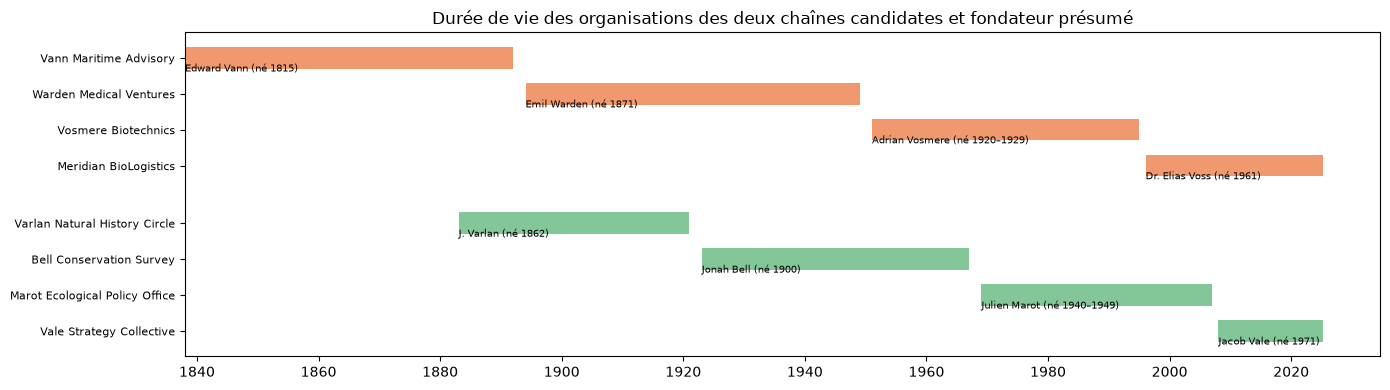

In [44]:
CHAINS = {
    "chaîne logistique / médicale": ["REG-NDH-01015", "REG-VLN-01016", "REG-NDH-01017", "REG-VLN-01001"],
    "chaîne écologie / politique": ["REG-KNT-01018", "REG-AVL-01019", "REG-VLN-01020", "REG-VLN-01006"],
}
ent_by_id = ent.set_index("registration_number")

fig, ax = plt.subplots(figsize=(14, 4))
y = 0
ticks = []
labels = []
for chain in CHAINS:
    color = "#31a354"
    if ("logistique" in chain):
        color = "#e6550d"
    for reg in CHAINS[chain]:
        e = ent_by_id.loc[reg]
        # une entite encore active va jusqu'a la date de reference
        end = REF_DATE
        if (e.current_status == "dissolved"):
            end = e.last_filing_date
        ax.barh(y, (end - e.registration_date).days, left=e.registration_date, height=0.6, color=color, alpha=0.6)
        ax.text(e.registration_date, y + 0.38, f"{e.full_name} (né {e.birth_year_or_age_band})", fontsize=7)
        ticks.append(y)
        labels.append(e.legal_name)
        y += 1
    # petit espace entre les deux chaines
    y += 0.6
ax.set_yticks(ticks)
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_title("Durée de vie des organisations des deux chaînes candidates et fondateur présumé")
plt.tight_layout()
plt.savefig(OUT / "chaines_organisations.png", dpi=150)
plt.show()

In [45]:
lic_by_person = lic.set_index("person_id")
pe_by_reg = pe.set_index("registration_number")

rows = []
for chain in CHAINS:
    for reg in CHAINS[chain]:
        f = first_officer.loc[reg]
        person_id = pid[("officer_filings", f.filing_id)]
        initials = ""
        for word in normalize_name(f.full_name).split():
            initials += word[0].upper()

        # licence de la meme personne, si elle en a une
        license_number = np.nan
        issue_date = pd.NaT
        meetings = 0
        if (person_id in lic_by_person.index):
            license_number = lic_by_person.loc[person_id, "license_number"]
            issue_date = lic_by_person.loc[person_id, "license_issue_date"]
            if (license_number in vol.index):
                meetings = int(vol.loc[license_number, "rencontres"])

        rows.append({
            "chaine": chain,
            "full_name": f.full_name,
            "initiales": initials,
            "birth_year_or_age_band": f.birth_year_or_age_band,
            "registration_number": reg,
            "appointment_date": f.appointment_date,
            "cessation_date": f.cessation_date,
            "license_number": license_number,
            "license_issue_date": issue_date,
            "partenaire_ERP": pe_by_reg.loc[reg, "partner_code"],
            "integration_ERP": pe_by_reg.loc[reg, "onboarding_date"],
            "rencontres_signees": meetings
        })
chain_view = pd.DataFrame(rows)
chain_view

,chaine,full_name,initiales,birth_year_or_age_band,registration_number,appointment_date,cessation_date,license_number,license_issue_date,partenaire_ERP,integration_ERP,rencontres_signees
0,chaîne logistique / médicale,Edward Vann,EV,1815,REG-NDH-01015,1840-01-01,1888-12-31,NaN,NaT,BP-30013,2001-02-01,0
1,chaîne logistique / médicale,Emil Warden,EW,1871,REG-VLN-01016,1895-01-01,1943-12-31,LIC-VLN-MED-1001,1895-07-01,BP-30005,2013-06-01,147
2,chaîne logistique / médicale,Adrian Vosmere,AV,1920–1929,REG-NDH-01017,1952-01-01,1991-12-31,NaN,NaT,BP-30038,2009-03-01,0
3,chaîne logistique / médicale,Dr. Elias Voss,EV,1961,REG-VLN-01001,1996-01-01,NaT,NaN,NaT,BP-30078,2011-07-01,0
4,chaîne écologie / politique,J. Varlan,JV,1862,REG-KNT-01018,1885-01-01,1918-12-31,LIC-KNT-RES-1007,1886-07-01,BP-30022,2008-11-01,0
5,chaîne écologie / politique,Jonah Bell,JB,1900,REG-AVL-01019,1924-01-01,1963-12-31,LIC-AVL-RES-1008,1924-07-01,BP-30059,2004-12-01,0
6,chaîne écologie / politique,Julien Marot,JM,1940–1949,REG-VLN-01020,1970-01-01,2004-12-31,LIC-VLN-ENV-1009,1970-07-01,BP-30058,2004-11-01,0
7,chaîne écologie / politique,Jacob Vale,JV,1971,REG-VLN-01006,2008-01-01,NaT,NaN,NaT,BP-30044,2009-09-01,0


**Deux chaînes de succession.** Le calcul automatique (dissolution puis création 0 à 5 ans plus tard) fait apparaître deux suites régulières de 4 organisations. Chaque organisation naît **2 à 3 ans** après la disparition de la précédente, et son activité prolonge la précédente :

| Chaîne | Organisations | Fondateurs présumés (naissance) | Initiales |
|---|---|---|---|
| logistique / médicale | Vann Maritime (1838-1891) → Warden Medical (1894-1948) → Vosmere Biotechnics (1951-1994) → Meridian BioLogistics (1996-) | Edward Vann (1815), Emil Warden (1871), Adrian Vosmere (1920-29), Elias Voss (1961) | E.V. / E.W. / A.V. / E.V. |
| écologie / politique | Varlan Circle (1883-1920) → Bell Survey (1923-1966) → Marot Policy Office (1969-2006) → Vale Strategy (2008-) | J. Varlan (1862), Jonah Bell (1900), Julien Marot (1940-49), Jacob Vale (1971) | J.V. / J.B. / J.M. / J.V. |

Les autres successions détectées (Bell → Nivren Maritime, Marot → Threshold Earth) n'ont ni activité ni fondateur comparables : ce sont des coïncidences de calendrier.

Dans chaque chaîne, le mandat d'un fondateur s'arrête 4 à 9 ans avant que le suivant n'apparaisse, avec un âge déclaré de 21 à 37 ans au début du mandat. Toutes les entités des deux chaînes sont **partenaires ERP**, y compris les dissoutes. Les licences de J. Varlan, Jonah Bell et Julien Marot sont toujours `active`, et celle d'Emil Warden est encore utilisée. Plusieurs documents publics (PUB-510043, PUB-510076, PUB-510033, PUB-510044) évoquent la même adresse de réexpédition (« Wren Street »), les mêmes associés et la même formule (« make the conditions ordinary ») chez Vosmere, Bell, Marot et Voss/Vale. Ils parlent explicitement d'une **piste de continuité d'alias, non prouvée**. Ces documents relèvent du volet textes (développeur 6) et sont cités ici comme indices à vérifier.

### 7.2 Synthèse : exemples de liens étayés ou incertains

| # | Lien | Statut | Éléments vérifiables | Ce qui manque |
|---|---|---|---|---|
| 1 | Licence LIC-VLN-MED-1001 (Emil Warden, 1895) utilisée pour 147 rencontres en 2015-2025 | **étayé** (fait) | jointure exacte `attending_license_number` ; date de délivrance ; naissance 1871 (FLG-000002) | l'identité réelle du signataire |
| 2 | Licence LIC-VLN-MED-1006 (Farah Havel) utilisée avant sa délivrance (2026) | **étayé** (fait) | 136 rencontres antérieures à `license_issue_date` | erreur de saisie ou licence fictive ? |
| 3 | Dr. Lysa Quen, à la fois auditrice publique (Orison Medical Audit Board) et médecin d'Asterion | **étayé** (confiance moyenne sur l'identité) | APT-000007 + LIC-VLN-MED-1004 (même nom, même région, auditrice médicale de spécialité) + 121 rencontres | année de naissance absente côté licence |
| 4 | Filières public → privé (AARA → Belen ; Orison → Vale Strategy ; Ministère → Lantern ; Asterion → Tembara) | **étayé** | 19 transitions datées, identités de confiance élevée/moyenne | motifs des départs |
| 5 | Rayan Belen régulateur agricole et président de Belen Agro-Industries en même temps | **étayé** | FLG-000018 + APT-000014, chevauchement 1981-1992 | — |
| 6 | Organisations dissoutes réactivées comme partenaires ERP | **étayé** (fait), intention **incertaine** | 5 partenaires, clé exacte, `onboarding_date` > `last_filing_date` | les flux réellement passés par ces partenaires (volet logistique) |
| 7 | Whitehaven Strategic Holdings domiciliée chez Meridian | **étayé** | adresse enregistrée = installation FCL-1011 exploitée par BP-30078 | lien capitalistique (aucun `parent_registration_number`) |
| 8 | Vann → Warden → Vosmere → Voss et Varlan → Bell → Marot → Vale sont une même personne par chaîne | **incertain** | successions régulières, initiales, licences anciennes actives, documents d'archive | aucune clé commune ; noms et naissances différents. En l'état, ces liens **ne permettent pas** d'affirmer une identité |
| 9 | Calen Elen = Jalen Elen, Daria Garen = Daria Maren, etc. | **rejeté** | naissances incompatibles ou régions différentes | — |

## 8. Limites

- **Rapprochement des personnes** : sans identifiant commun entre les trois registres, la fusion repose sur le nom, la naissance et la région. Les nominations publiques sans année de naissance (9) et les licences (aucune naissance) ne peuvent atteindre qu'une confiance **moyenne**.
- **Seuils arbitraires** : similarité ≥ 0,8, durée < 2 ans, succession ≤ 5 ans, ancienneté de licence > 60 ans. Ils ont été choisis pour leur lisibilité, pas optimisés ; aucune analyse de sensibilité n'a été faite.
- **Date de référence** : les postes ouverts sont prolongés jusqu'au 2025-03-31 ; une autre date changerait les durées mais pas les chevauchements détectés.
- **Graphe** : il ne contient que les liens déclarés dans les registres ; les liens logistiques et cliniques sont analysés à part (§5, §6) pour ne pas mélanger des relations de nature différente. Les centralités dépendent de la résolution d'identité (§2.5) et du champ `primary_facility_license`, qui décrit une affectation actuelle : le degré élevé de Threshold Earth Avelora Laboratory traduit ce rattachement administratif, pas une activité réelle sur place.
- **Interprétation** : un même nom, une même adresse ou une licence réutilisée sont des **indices** ; ils ne prouvent ni une identité ni une fraude. Les références documentaires citées en §7 doivent être vérifiées par le volet textes (développeur 6).

## 9. Exports

In [46]:
rows = []
for node, data in G.nodes(data=True):
    row = {"id": node}
    row.update(data)
    rows.append(row)
nodes = pd.DataFrame(rows)
nodes = nodes.merge(centrality[["degré", "intermédiarité"]], left_on="id", right_index=True, how="left")

rows = []
for u, v, data in G.edges(data=True):
    rows.append({
        "source": u,
        "target": v,
        "relation": data["relation"],
        "weight": data["weight"],
        "records": ";".join(data["records"])
    })
edges = pd.DataFrame(rows)

exports = {
    "graphe_noeuds.csv": nodes,
    "graphe_aretes.csv": edges,
    "postes.csv": posts,
    "chevauchements.csv": overlaps,
    "volumes_sante_praticiens.csv": vol.reset_index(),
    "volumes_sante_etablissements.csv": fac_vol.reset_index(),
    "partenaires_registre.csv": pe,
    "successions_organisations.csv": succession,
}
for filename in exports:
    exports[filename].to_csv(OUT / filename, index=False)

files = []
for path in OUT.iterdir():
    files.append(path.name)
sorted(files)

['chaines_organisations.png',
 'chevauchements.csv',
 'chronologie_mandats.png',
 'graphe_aretes.csv',
 'graphe_noeuds.csv',
 'graphe_registres.png',
 'paires_candidates.csv',
 'partenaires_registre.csv',
 'postes.csv',
 'successions_organisations.csv',
 'table_correspondances_personnes.csv',
 'volumes_sante.png',
 'volumes_sante_etablissements.csv',
 'volumes_sante_praticiens.csv']